# FYDP-2 · Spatially-Grounded, Topology-Aware Graph-RAG for 3D Scene Reasoning
### Reproduction of *Open-World 3D Scene Graph Generation for Retrieval-Augmented Reasoning* (arXiv:2511.05894, AAAI-26) + our proposed method

**Zero setup.** No `pip install`, no GPU, no internet. Only libraries that ship with every Kaggle image:
`numpy · pandas · scipy · networkx · scikit-learn · matplotlib`. Attach your dataset and press **Run All**.

| Part | What it does | Paper equations |
|---|---|---|
| **0** | Auto-discovers `objects.json`, `relationships.json`, every `semseg.v2.json`, and any RGB-D `sequence.zip` | – |
| **A** | **Reproduces Paper-1 Stage 1 (geometry)** on RGB-D: back-projection, pose-noise model, multi-frame fusion, object merging, OBB fitting, best-view selection | Eq. 4–16 |
| **B** | **Reproduces Paper-1 reliable-object filtering + its Table-4 ablation**, then tests **our Adaptive Spatial Relevance** at an equal VLM budget, under scale shift, with ablations | Eq. 17–19 vs ours |
| **C** | **Reproduces Paper-1 retrieval** (label-centred chunks + top-k cosine) and compares with **our topology-aware multi-hop retrieval** on a synthetic multi-hop QA benchmark built from 3DSSG | Eq. 22–26 vs ours |
| **D** | **End-to-end**: graph built with Paper-1 filter vs ours → downstream multi-hop QA | – |
| **E** | Summary tables + figures written to `/kaggle/working/` for the report | – |

**Honest scope (write this in your paper).** Paper-1's perception stack uses DINOv2/MobileSAM, LLaVA and Qwen2-VL-72B on a 45 GB GPU.
We replace the three learned perception models with *oracle* equivalents from the dataset annotations
(GT instance masks → segmentation, GT labels → LLaVA labelling, GT predicates on proposed pairs → Qwen2-VL relation prediction).
Every geometric and retrieval step is re-implemented from the equations. Because the oracles are identical for the baseline and for our method,
all comparisons isolate exactly the two components our proposal changes: **spatial candidate filtering** and **graph retrieval**.

In [1]:
import os, io, re, json, time, math, random, zipfile, itertools, warnings
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- configuration (edit freely) ----------------
N_QA_SCANS      = 400      # 3DSSG scans used for the retrieval benchmark (Part C); max 1335
QA_PER_TYPE     = 4        # questions generated per scan per question type
FRAME_STRIDE    = 2        # use every k-th RGB-D frame in Part A
BACKGROUND      = {"floor", "ceiling"}   # removed as in Paper-1 ("background elements (e.g. floor, ceiling) are filtered out")
PAPER_DTHRESH   = 0.5      # Paper-1 Eq.19 distance threshold (metres)
PAPER_TOPK      = 3        # Paper-1 top-k chunks
# --------------------------------------------------------------

SEARCH_ROOTS = [r for r in ["/kaggle/input", os.environ.get("FYDP_DATA", "./data")] if os.path.isdir(r)]
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./fydp_outputs")
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
C_PAPER, C_OURS, C_ALT, C_GREY = "#1f5aa6", "#e08a00", "#2a9d8f", "#9aa0a6"

def walk_files(name):
    hits = []
    for root in SEARCH_ROOTS:
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if not d.startswith(".")]
            if name in fn:
                hits.append(os.path.join(dp, name))
    return hits

OBJ_JSON = (walk_files("objects.json") or [None])[0]
REL_JSON = (walk_files("relationships.json") or [None])[0]
SEMSEG = {}
for p in walk_files("semseg.v2.json"):
    SEMSEG.setdefault(os.path.basename(os.path.dirname(p)), p)   # duplicates of the same scan are ignored
SCAN_DIRS = {sid: os.path.dirname(p) for sid, p in SEMSEG.items()}
PAIR_CSV = [p for p in walk_files("all_scene_pairs.csv") if "multi_scene_results" in p]
PAIR_CSV = PAIR_CSV[0] if PAIR_CSV else None

print("search roots   :", SEARCH_ROOTS)
print("objects.json   :", OBJ_JSON)
print("relationships  :", REL_JSON)
print("scans w/ geometry (semseg.v2.json):", len(SEMSEG))
for sid, d in SCAN_DIRS.items():
    has_seq = os.path.exists(os.path.join(d, "sequence.zip")) or os.path.isdir(os.path.join(d, "sequence"))
    has_ply = os.path.exists(os.path.join(d, "labels.instances.annotated.v2.ply"))
    print(f"   {sid}  RGB-D={'yes' if has_seq else 'no'}  instance-mesh={'yes' if has_ply else 'no'}")
print("output folder  :", OUT)
assert OBJ_JSON and REL_JSON, "Attach the dataset that contains 3DSSG objects.json and relationships.json"

search roots   : ['/kaggle/input']
objects.json   : /kaggle/input/datasets/rokiajannat/3dssgproject/3DSSG/objects.json
relationships  : /kaggle/input/datasets/rokiajannat/3dssgproject/3DSSG/relationships.json
scans w/ geometry (semseg.v2.json): 10
   7272e161-a01b-20f6-8b5a-0b97efeb6545  RGB-D=no  instance-mesh=no
   c7895f78-339c-2d13-82bb-cc990cbbc90f  RGB-D=no  instance-mesh=no
   baf0a8fb-26d4-2033-8a28-2001356bbb9a  RGB-D=no  instance-mesh=no
   422885e0-192d-25fc-844a-62e395291839  RGB-D=no  instance-mesh=no
   bf9a3dd3-45a5-2e80-8163-8a5b2573aca4  RGB-D=no  instance-mesh=no
   6a36053f-fa53-2915-9579-3938283bc154  RGB-D=no  instance-mesh=no
   6e67e550-1209-2cd0-8294-7cc2564cf82c  RGB-D=no  instance-mesh=no
   f62fd5fd-9a3f-2f44-883a-1e5cf819608e  RGB-D=no  instance-mesh=no
   4731977e-f9f7-2a1a-955d-8cdd12ec7337  RGB-D=no  instance-mesh=no
   ab835faa-54c6-29a1-9b55-1a5217fcba19  RGB-D=no  instance-mesh=no
output folder  : /kaggle/working


## 0 · Load the 3DSSG scene graphs (ground truth, 1,335 scans)
Relationship tuples are `[subject_id, object_id, predicate_id, predicate]`, read as *subject — predicate → object*
(e.g. `chair  standing on  floor`). Predicates are grouped so that the *comparative* ones (`same color`, `bigger than`, …),
which are not spatially local, never count as a pair the spatial filter should propose.

In [2]:
PRED_GROUP = {}
for p in ["supported by", "attached to", "standing on", "lying on", "hanging on", "connected to", "leaning against",
          "part of", "belonging to", "build in", "standing in", "cover", "lying in", "hanging in", "inside"]:
    PRED_GROUP[p] = "support_contact"
PRED_GROUP["close by"] = "proximity"
for p in ["left", "right", "front", "behind"]:
    PRED_GROUP[p] = "directional"
LOCAL_PREDS = set(PRED_GROUP)                    # predicates a spatial pair filter should recover
QA_PREDS = LOCAL_PREDS                           # predicates used to build reasoning chains

with open(OBJ_JSON) as f: _objs = json.load(f)["scans"]
with open(REL_JSON) as f: _rels = json.load(f)["scans"]
rel_map = {s["scan"]: s["relationships"] for s in _rels}

SCENES = {}          # scan_id -> dict(labels, attrs, edges)
for s in _objs:
    sid = s["scan"]
    if sid not in rel_map: continue
    labels = {int(o["id"]): o["label"].strip().lower() for o in s["objects"]}
    attrs  = {int(o["id"]): o.get("attributes", {}) for o in s["objects"]}
    edges = sorted({(int(a), int(b), p.strip().lower()) for a, b, _, p in rel_map[sid]
                    if int(a) in labels and int(b) in labels and int(a) != int(b)})
    SCENES[sid] = dict(labels=labels, attrs=attrs, edges=edges)

n_obj = [len(v["labels"]) for v in SCENES.values()]
n_edge = [len(v["edges"]) for v in SCENES.values()]
print(f"scans with graphs: {len(SCENES)} | objects/scan: {np.mean(n_obj):.1f} | edges/scan: {np.mean(n_edge):.1f}")
pc = Counter(p for v in SCENES.values() for _, _, p in v["edges"])
print("most frequent local predicates:", [(p, c) for p, c in pc.most_common() if p in LOCAL_PREDS][:10])

scans with graphs: 1335 | objects/scan: 29.2 | edges/scan: 407.5
most frequent local predicates: [('right', 45357), ('left', 45357), ('close by', 26500), ('front', 24165), ('behind', 24165), ('attached to', 12761), ('standing on', 12672), ('lying on', 3571), ('hanging on', 2423), ('supported by', 1498)]


## Geometry utilities (exact oriented-box maths, no extra libraries)
3RScan boxes are gravity-aligned (one axis is vertical), so a box is an extruded convex polygon.
That lets us compute **exact** 3D IoU (Paper-1 Eq. 18) and the exact **surface gap** between two boxes with 2-D polygon clipping.

In [3]:
def box_from_semseg(g):
    ob = g["obb"]
    A = np.array(ob["normalizedAxes"], float).reshape(3, 3)       # rows = axes
    return make_box(np.array(ob["centroid"], float), A, np.array(ob["axesLengths"], float))

def make_box(c, A, L):
    k = int(np.argmax(np.abs(A[:, 2])))                             # vertical axis
    h = [i for i in range(3) if i != k]
    a1, a2 = A[h[0], :2], A[h[1], :2]
    a1 = a1 / (np.linalg.norm(a1) + 1e-12); a2 = a2 / (np.linalg.norm(a2) + 1e-12)
    e1, e2 = L[h[0]] / 2, L[h[1]] / 2
    cx = c[:2]
    poly = np.array([cx + e1*a1 + e2*a2, cx - e1*a1 + e2*a2, cx - e1*a1 - e2*a2, cx + e1*a1 - e2*a2])
    if poly_area_signed(poly) < 0: poly = poly[::-1]
    H = L[k]
    return dict(c=c, A=A, L=L, poly=poly, zmin=c[2]-H/2, zmax=c[2]+H/2, area=abs(poly_area_signed(poly)),
                vol=float(np.prod(L)), s=0.5*float(np.linalg.norm(L)))

def poly_area_signed(P):
    x, y = P[:, 0], P[:, 1]
    return 0.5 * float(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def clip_poly(subject, clip):                                        # Sutherland–Hodgman, both convex CCW
    out = list(subject)
    for i in range(len(clip)):
        A, B = clip[i], clip[(i+1) % len(clip)]
        inp, out = out, []
        if not inp: break
        def inside(P): return (B[0]-A[0])*(P[1]-A[1]) - (B[1]-A[1])*(P[0]-A[0]) >= -1e-12
        def inter(P, Q):
            d1 = np.array(Q) - np.array(P); d2 = B - A
            den = d1[0]*d2[1] - d1[1]*d2[0]
            if abs(den) < 1e-15: return P
            t = ((A[0]-P[0])*d2[1] - (A[1]-P[1])*d2[0]) / den
            return np.array(P) + t*d1
        S = inp[-1]
        for E in inp:
            if inside(E):
                if not inside(S): out.append(inter(S, E))
                out.append(E)
            elif inside(S):
                out.append(inter(S, E))
            S = E
    return np.array(out) if len(out) >= 3 else None

def seg_dist(P, A, B):
    AB = B - A; t = np.clip(np.dot(P-A, AB) / (np.dot(AB, AB) + 1e-12), 0, 1)
    return float(np.linalg.norm(P - (A + t*AB)))

def pair_geometry(bi, bj):
    """IoU3D (Eq.18), xy-overlap area, exact surface gap between two gravity-aligned boxes."""
    I = clip_poly(bi["poly"], bj["poly"])
    a_xy = abs(poly_area_signed(I)) if I is not None else 0.0
    z_ov = max(0.0, min(bi["zmax"], bj["zmax"]) - max(bi["zmin"], bj["zmin"]))
    inter = a_xy * z_ov
    iou = inter / (bi["vol"] + bj["vol"] - inter + 1e-12)
    if a_xy > 1e-9:
        gxy = 0.0
    else:
        gxy = min(min(seg_dist(p, bj["poly"][k], bj["poly"][(k+1) % 4]) for p in bi["poly"] for k in range(4)),
                  min(seg_dist(p, bi["poly"][k], bi["poly"][(k+1) % 4]) for p in bj["poly"] for k in range(4)))
    gz = max(0.0, bi["zmin"] - bj["zmax"], bj["zmin"] - bi["zmax"])
    return dict(iou=iou, a_xy=a_xy, z_ov=z_ov, gap=math.hypot(gxy, gz), gap_xy=gxy, gap_z=gz)

def load_geometry(sid):
    with open(SEMSEG[sid]) as f: d = json.load(f)
    boxes, labels = {}, {}
    for g in d["segGroups"]:
        boxes[int(g["id"])] = box_from_semseg(g); labels[int(g["id"])] = g["label"].strip().lower()
    return boxes, labels

GEO = {sid: load_geometry(sid) for sid in SEMSEG if sid in SCENES}
print("geometry scans usable (also have a 3DSSG graph):", len(GEO))

geometry scans usable (also have a 3DSSG graph): 10


---
# Part A · Reproducing Paper-1 Stage 1 (multi-frame geometry) on real RGB-D
Runs on every attached scan that has an RGB-D `sequence(.zip)` **and** `labels.instances.annotated.v2.ply`.

| Paper-1 step | Here |
|---|---|
| Frame model `I, D, K, T` (Eq. 4–5) | 3RScan depth (224×172, depth-intrinsics), camera→world poses |
| Pose uncertainty in 𝔰𝔢(3) (Eq. 6–7) | Gaussian twist noise applied through the exponential map (used for the robustness study) |
| Open-vocab segmentation | **oracle**: each back-projected pixel takes the instance id of the nearest annotated mesh vertex (≤ 4 cm) |
| Back-projection (Eq. 11–12) | `X_c = K⁻¹[u v 1]ᵀ D(u,v)`, `X_w = T X_c` |
| Merging every L frames (Eq. 13) | label-consistent + geometric-consistency merging of per-frame detections into tracks (no instance ids used) |
| OBB `b=(c,ℓ,R)` (Eq. 8) | gravity-aligned PCA box on robust (2–98 %) extents |
| Best-view (Eq. 15–16) | `argmax A·V^γ − λ·D(T_first, T)` |
| LLaVA labelling | **oracle** label (majority GT label of the track's points) |

In [4]:
def read_pgm(b):
    toks, i = [], 0
    while len(toks) < 4:
        while b[i:i+1].isspace(): i += 1
        if b[i:i+1] == b"#":
            while b[i:i+1] not in (b"\n", b"\r"): i += 1
            continue
        s = i
        while not b[i:i+1].isspace(): i += 1
        toks.append(b[s:i])
    i += 1
    w, h, mx = int(toks[1]), int(toks[2]), int(toks[3])
    dt = ">u2" if mx > 255 else "u1"
    return np.frombuffer(b[i:i + w*h*np.dtype(dt).itemsize], dtype=dt).reshape(h, w)

class Sequence:
    """Reads 3RScan RGB-D frames either from sequence.zip or an extracted sequence/ folder."""
    def __init__(self, scan_dir):
        zp, dp = os.path.join(scan_dir, "sequence.zip"), os.path.join(scan_dir, "sequence")
        if os.path.isdir(dp) and any(x.endswith(".depth.pgm") for x in os.listdir(dp)):
            self._p = {x: os.path.join(dp, x) for x in os.listdir(dp)}
            self.read = lambda n: open(self._p[n], "rb").read()
        else:
            z = zipfile.ZipFile(zp); self._p = {os.path.basename(x): x for x in z.namelist()}
            self.read = lambda n: z.read(self._p[n])
        info = {}
        for line in self.read("_info.txt").decode().splitlines():
            if "=" in line:
                k, v = line.split("=", 1); info[k.strip()] = v.strip()
        self.info = info
        Kd = np.array(info["m_calibrationDepthIntrinsic"].split(), float).reshape(4, 4)[:3, :3]
        Kc = np.array(info["m_calibrationColorIntrinsic"].split(), float).reshape(4, 4)[:3, :3]
        self.Kd, self.Kc, self.shift = Kd, Kc, float(info.get("m_depthShift", 1000))
        self.frames = sorted(int(x[6:12]) for x in self._p if x.endswith(".depth.pgm"))
    def depth(self, i): return read_pgm(self.read(f"frame-{i:06d}.depth.pgm")).astype(np.float32) / self.shift
    def pose(self, i):  return np.loadtxt(io.BytesIO(self.read(f"frame-{i:06d}.pose.txt")))
    def color(self, i): return plt.imread(io.BytesIO(self.read(f"frame-{i:06d}.color.jpg")), format="jpg")

def read_instance_ply(path):
    with open(path) as f:
        hdr = []
        while True:
            l = f.readline(); hdr.append(l)
            if l.startswith("end_header"): break
        nv = int([h for h in hdr if h.startswith("element vertex")][0].split()[-1])
        props = [h.split()[-1] for h in hdr if h.startswith("property") and "list" not in h]
        V = np.loadtxt(f, max_rows=nv)
    return V[:, :3], V[:, props.index("objectId")].astype(int)

def so3_exp(w):
    th = np.linalg.norm(w)
    if th < 1e-12: return np.eye(3)
    k = w / th; Kx = np.array([[0, -k[2], k[1]], [k[2], 0, -k[0]], [-k[1], k[0], 0]])
    return np.eye(3) + math.sin(th)*Kx + (1-math.cos(th))*Kx@Kx

def perturb_pose(T, sig_t, sig_r_deg, rng):
    """Eq. 6-7: sample a twist (xi, omega) ~ N(0, Sigma_pose) and left-multiply exp(twist)."""
    if sig_t == 0 and sig_r_deg == 0: return T
    E = np.eye(4); E[:3, :3] = so3_exp(rng.normal(0, math.radians(sig_r_deg), 3)); E[:3, 3] = rng.normal(0, sig_t, 3)
    return E @ T

def fit_obb(P):
    """Eq. 8: gravity-aligned oriented box from fused points (robust extents)."""
    xy = P[:, :2] - P[:, :2].mean(0)
    evals, evecs = np.linalg.eigh(np.cov(xy.T) + 1e-9*np.eye(2))
    a1 = evecs[:, 1]; a2 = np.array([-a1[1], a1[0]])
    p1, p2 = xy @ a1, xy @ a2
    lo1, hi1 = np.percentile(p1, [2, 98]); lo2, hi2 = np.percentile(p2, [2, 98]); lz, hz = np.percentile(P[:, 2], [2, 98])
    c = np.r_[P[:, :2].mean(0) + a1*(lo1+hi1)/2 + a2*(lo2+hi2)/2, (lz+hz)/2]
    A = np.array([[a1[0], a1[1], 0], [a2[0], a2[1], 0], [0, 0, 1.0]])
    L = np.maximum([hi1-lo1, hi2-lo2, hz-lz], 0.02)
    return make_box(c, A, np.array(L))

def run_stage1(sid, sig_t=0.0, sig_r=0.0, stride=FRAME_STRIDE, seed=SEED, keep_views=False, verbose=True):
    d = SCAN_DIRS[sid]; seq = Sequence(d)
    Vx, Vid = read_instance_ply(os.path.join(d, "labels.instances.annotated.v2.ply"))
    tree = cKDTree(Vx); gt_boxes, gt_labels = GEO[sid]
    rng = np.random.default_rng(seed); Kinv = np.linalg.inv(seq.Kd)
    tracks = []            # dict(label, keys:int64 voxel keys, pts:list, obs:list, gt:list)
    frames = seq.frames[::stride]
    VOX, MERGE_EVERY = 0.05, 10
    OFFS = np.array([(i, j, k) for i in (-1, 0, 1) for j in (-1, 0, 1) for k in (-1, 0, 1)])
    def keys(ijk): return (ijk[:, 0].astype(np.int64) + 10000) * 100000000 + (ijk[:, 1] + 10000) * 10000 + (ijk[:, 2] + 5000)
    def adjacency(ka, ijk_b):
        """fraction of voxels of b that touch (26-neighbourhood) voxels of a  -> geometric consistency"""
        dil = keys((ijk_b[:, None, :] + OFFS[None]).reshape(-1, 3)).reshape(len(ijk_b), 27)
        return np.isin(dil, ka).any(1).mean()
    def absorb(t, o):
        t["keys"] = np.union1d(t["keys"], o["keys"]); t["ijk"] = np.unique(np.vstack([t["ijk"], o["ijk"]]), axis=0)
        t["pts"] += o["pts"]; t["gt"] += o["gt"]; t["obs"] += o["obs"]
    for n_f, fi in enumerate(frames):
        D = seq.depth(fi); T = perturb_pose(seq.pose(fi), sig_t, sig_r, rng)
        v, u = np.nonzero((D > 0.1) & (D < 6.0))
        if len(u) == 0: continue
        Xc = (Kinv @ np.vstack([u, v, np.ones_like(u)])) * D[v, u]                  # Eq. 11
        Xw = (T[:3, :3] @ Xc + T[:3, 3:]).T                                          # Eq. 12
        dist, idx = tree.query(Xw, distance_upper_bound=0.04)
        ok = np.isfinite(dist); inst = np.full(len(u), -1); inst[ok] = Vid[idx[ok]]    # oracle segmentation
        for oid in np.unique(inst[inst > 0]):
            lab = gt_labels.get(int(oid))
            if lab is None or lab in BACKGROUND: continue
            m = inst == oid
            if m.sum() < 30: continue
            P = Xw[m]; ijk = np.unique(np.floor(P / VOX).astype(int), axis=0)
            det = dict(label=lab, keys=np.unique(keys(ijk)), ijk=ijk, pts=[P[::4]], gt=[int(oid)],
                       obs=[dict(P=P[::4], frame=fi, pix=(u[m], v[m]), pose=T)])
            # ---- Eq.13-style association: same label AND geometric consistency with an existing track
            best, best_s = None, 0.0
            for t in tracks:
                if t["label"] != lab: continue
                s_ = adjacency(t["keys"], ijk)
                if s_ > best_s: best, best_s = t, s_
            if best is not None and best_s >= 0.2: absorb(best, det)
            else: tracks.append(det)
        # ---- periodic track-level merging every L frames (Eq. 13 "objects are merged every L frames")
        if (n_f + 1) % MERGE_EVERY == 0 or n_f == len(frames) - 1:
            changed = True
            while changed:
                changed = False
                for i in range(len(tracks)):
                    for j in range(i + 1, len(tracks)):
                        ti, tj = tracks[i], tracks[j]
                        if ti["label"] != tj["label"]: continue
                        si, bi_ = (i, j) if len(ti["ijk"]) < len(tj["ijk"]) else (j, i)
                        if adjacency(tracks[bi_]["keys"], tracks[si]["ijk"]) >= 0.1:
                            absorb(tracks[bi_], tracks[si]); del tracks[si]; changed = True; break
                    if changed: break
    # ---- fuse, fit OBB, evaluate vs GT
    rows, rec_boxes, rec_labels = [], {}, {}
    for k, t in enumerate(tracks):
        P = np.concatenate(t["pts"])
        if len(P) < 50: continue
        b = fit_obb(P); maj = Counter(t["gt"]).most_common(1)[0][0]
        rec_boxes[k] = b; rec_labels[k] = t["label"]
        g = gt_boxes[maj]; pg = pair_geometry(b, g)
        rows.append(dict(track=k, label=t["label"], gt_id=maj, purity=Counter(t["gt"])[maj]/len(t["gt"]),
                         n_obs=len(t["obs"]), centroid_err=float(np.linalg.norm(b["c"]-g["c"])), iou_gt=pg["iou"]))
        # ---- best-view selection, Eq. 15-16  (A = projected area fraction, V = visibility, D = pose change)
        if keep_views:
            T0 = t["obs"][0]["pose"]; best_v, best_sc = None, -1e9
            for o in t["obs"]:
                A_ = len(o["pix"][0]) / (224*172)
                uu, vv = o["pix"]; bw = (uu.max()-uu.min()+1)*(vv.max()-vv.min()+1)
                V_ = len(uu) / bw                                   # fraction of the object's image box that is the object
                border = (uu.min() > 2) and (uu.max() < 221) and (vv.min() > 2) and (vv.max() < 169)
                V_ *= 1.0 if border else 0.5                         # truncated at the image border -> less visible
                Dp = np.linalg.norm(o["pose"][:3, :3]-T0[:3, :3]) + np.linalg.norm(o["pose"][:3, 3]-T0[:3, 3])
                sc = A_ * V_**2.0 - 0.001*Dp
                if sc > best_sc: best_sc, best_v = sc, o
            t["best_view"] = best_v
    df = pd.DataFrame(rows)
    n_gt = len({i for i, l in gt_labels.items() if l not in BACKGROUND})
    matched = df.gt_id.nunique() if len(df) else 0
    summary = dict(scan=sid, sigma_t=sig_t, sigma_r_deg=sig_r, frames=len(frames), gt_objects=n_gt, tracks=len(df),
                   gt_recovered=matched, over_segmentation=(len(df)-matched), mean_purity=df.purity.mean(),
                   centroid_err_med=df.centroid_err.median(), iou_gt_med=df.iou_gt.median())
    if verbose: print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in summary.items()})
    return summary, df, rec_boxes, rec_labels, tracks, seq

STAGE1_SCANS = [sid for sid, d in SCAN_DIRS.items() if sid in GEO and
                (os.path.exists(os.path.join(d, "sequence.zip")) or os.path.isdir(os.path.join(d, "sequence")))
                and os.path.exists(os.path.join(d, "labels.instances.annotated.v2.ply"))]
print("scans with RGB-D + instance mesh:", STAGE1_SCANS)
STAGE1 = {}
for sid in STAGE1_SCANS:
    t0 = time.time()
    STAGE1[sid] = run_stage1(sid, keep_views=True)
    print(f"   stage-1 time {time.time()-t0:.1f}s")

scans with RGB-D + instance mesh: []


### A.1 Reconstructed boxes vs. ground truth, and best views chosen by Eq. 15

In [5]:
if STAGE1:
    sid = STAGE1_SCANS[0]; summ, df1, rb, rl, tracks, seq = STAGE1[sid]
    display_df = df1.sort_values("centroid_err").round(3)
    print(display_df.head(12).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
    gb, gl = GEO[sid]
    for i, b in gb.items():
        if gl[i] in BACKGROUND: continue
        P = np.vstack([b["poly"], b["poly"][:1]]); ax[0].plot(P[:, 0], P[:, 1], color=C_GREY, lw=1.5)
    for k, b in rb.items():
        P = np.vstack([b["poly"], b["poly"][:1]]); ax[0].plot(P[:, 0], P[:, 1], color=C_OURS, lw=1.2, ls="--")
    ax[0].plot([], [], color=C_GREY, label="GT OBB (3RScan)"); ax[0].plot([], [], color=C_OURS, ls="--", label="reconstructed OBB (Eq. 8–13)")
    ax[0].set_aspect("equal"); ax[0].legend(loc="upper right", fontsize=8); ax[0].set_title("Top-down: reconstructed vs GT boxes")
    ax[1].hist(df1.centroid_err, bins=20, color=C_PAPER); ax[1].set_xlabel("centroid error (m)"); ax[1].set_ylabel("#objects")
    ax[1].set_title(f"median centroid error {df1.centroid_err.median():.3f} m, median IoU {df1.iou_gt.median():.2f}")
    plt.tight_layout(); plt.savefig(f"{OUT}/figA1_stage1_reconstruction.png", bbox_inches="tight"); plt.show()

    # best-view crops (colour image, projected with colour intrinsics)
    show = [t for t in tracks if t.get("best_view") is not None and t["label"] not in ("wall", "cabinet", "kitchen cabinet")]
    show = sorted(show, key=lambda t: -len(t["obs"]))[:8]
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for a, t in zip(axes.ravel(), show):
        o = t["best_view"]; img = seq.color(o["frame"]); Tinv = np.linalg.inv(o["pose"])
        Pc = (Tinv[:3, :3] @ o["P"].T + Tinv[:3, 3:]); uvw = seq.Kc @ Pc; uv = uvw[:2] / uvw[2]
        H, W = img.shape[:2]
        x0, x1 = np.clip(np.percentile(uv[0], [2, 98]), 0, W-1).astype(int); y0, y1 = np.clip(np.percentile(uv[1], [2, 98]), 0, H-1).astype(int)
        pad = 25; crop = img[max(0, y0-pad):y1+pad, max(0, x0-pad):x1+pad]
        a.imshow(np.rot90(crop, -1)); a.set_title(f"{t['label']} · frame {o['frame']}", fontsize=9)
        a.axis("off")
    plt.suptitle("Best view per object selected with Paper-1 Eq. 15 (A·V^γ − λD)"); plt.tight_layout()
    plt.savefig(f"{OUT}/figA2_best_views.png", bbox_inches="tight"); plt.show()
else:
    print("No RGB-D sequence attached - Part A skipped (Parts B–D still run).")

No RGB-D sequence attached - Part A skipped (Parts B–D still run).


### A.2 Robustness to pose noise (Paper-1 Eq. 6–7)
Same pipeline, but every camera pose is perturbed with twist noise of increasing magnitude.

In [6]:
POSE_NOISE = [(0.0, 0.0), (0.01, 0.5), (0.02, 1.0), (0.05, 2.0), (0.10, 4.0)]
pose_rows = []
if STAGE1:
    for st, sr in POSE_NOISE:
        s_, d_, rb_, rl_, _, _ = run_stage1(STAGE1_SCANS[0], sig_t=st, sig_r=sr, stride=FRAME_STRIDE*2, verbose=False)
        pose_rows.append(s_)
    POSE_DF = pd.DataFrame(pose_rows)
    print(POSE_DF[["sigma_t", "sigma_r_deg", "tracks", "gt_recovered", "over_segmentation", "mean_purity", "centroid_err_med", "iou_gt_med"]].round(3).to_string(index=False))
    POSE_DF.to_csv(f"{OUT}/tableA2_pose_noise.csv", index=False)

---
# Part B · Spatial candidate filtering: Paper-1 (Eq. 17–19) vs. our Adaptive Spatial Relevance
**Why this matters.** In Paper-1 every pair that survives the filter is sent to Qwen2-VL-72B, the most expensive stage
(their ablation, Table 4). A pair that is filtered out can never become an edge in the scene graph.
So the right comparison is **recall of true relationships at the same number of VLM calls**.

**Positives** = object pairs with at least one GT 3DSSG relationship from the *local* groups
(support/contact, proximity, directional). Background (floor, ceiling) removed as in Paper-1.

**Our score** (slides 8–10) — every term is scale-normalised, so no metre threshold appears anywhere:

| term | definition | intuition |
|---|---|---|
| `S_dist` | `exp(−d / (s_i + s_j))`, `s` = half-diagonal | distance measured in object sizes |
| `S_IoU` | `max(IoU₃D, exp(−gap / (0.1(s_i+s_j))))` | Paper-1 overlap **or** surface contact |
| `S_position` | `max(xy-overlap·exp(−vgap/…), z-overlap·exp(−gap_xy/…))` | stacked (on/under) or side-by-side at same height |
| `S_context` | `exp(−d / (0.25·room_diag)) / √(1+ρ)` | room scale and local density ρ |

`S_spatial = α·S_dist + β·S_IoU + γ·S_position + δ·S_context`
* **Ours-HC** – hand-set equal weights (0.25 each): *no training at all*.
* **Ours-LR** – α…δ learned by logistic regression (slide 10), evaluated out-of-sample
  (leave-one-scene-out if ≥ 3 geometry scans are attached, otherwise 5-fold CV grouped by object).
* **Ours-LR-full** – same learner on the raw scale-invariant features behind the four terms (a learned `f(d, s, r, ρ, p)`).

> **Scaling up:** Part B uses every scan that has a `semseg.v2.json`. Each file is only ~30 KB; fetch more with
> `python download_3RScan.py -o 3RScan --id <scan_id> --type semseg.v2.json` and add them to the Kaggle dataset —
> the notebook switches to leave-one-scene-out automatically.

In [7]:
def room_diag(boxes):
    allc = np.array([b["c"] for b in boxes.values()]); ext = np.array([b["L"].max() for b in boxes.values()])
    lo, hi = (allc - ext[:, None]/2).min(0), (allc + ext[:, None]/2).max(0)
    return float(np.linalg.norm(hi - lo))

def pair_table(sid, boxes=None, labels=None, scale=1.0):
    """All unordered non-background pairs of a scan with Paper-1 geometry and our four terms."""
    gb, gl = GEO[sid]
    boxes = boxes if boxes is not None else gb
    labels = labels if labels is not None else gl
    if scale != 1.0:
        boxes = {k: make_box(b["c"]*scale, b["A"], b["L"]*scale) for k, b in boxes.items()}
    ids = [i for i in boxes if labels.get(i, "") not in BACKGROUND]
    R = room_diag({i: boxes[i] for i in ids}) if ids else 1.0
    C = np.array([boxes[i]["c"] for i in ids]); tree = cKDTree(C)
    rel = defaultdict(set)
    for a, b, p in SCENES[sid]["edges"]:
        rel[frozenset((a, b))].add(p)
    rows = []
    for x in range(len(ids)):
        for y in range(x+1, len(ids)):
            i, j = ids[x], ids[y]; bi, bj = boxes[i], boxes[j]
            g = pair_geometry(bi, bj)
            d = float(np.linalg.norm(bi["c"] - bj["c"])); ss = bi["s"] + bj["s"]
            mid = (bi["c"] + bj["c"]) / 2
            rho = len(tree.query_ball_point(mid, r=ss)) - 2
            xy_ov = g["a_xy"] / (min(bi["area"], bj["area"]) + 1e-9)
            z_ov = g["z_ov"] / (min(bi["zmax"]-bi["zmin"], bj["zmax"]-bj["zmin"]) + 1e-9)
            S_dist = math.exp(-d / ss)
            S_iou = max(g["iou"], math.exp(-g["gap"] / (0.1*ss)))
            S_pos = max(xy_ov * math.exp(-g["gap_z"] / (0.1*ss)), min(z_ov, 1) * math.exp(-g["gap_xy"] / (0.25*ss)))
            S_ctx = math.exp(-d / (0.25*R)) / math.sqrt(1 + max(rho, 0))
            preds = rel.get(frozenset((i, j)), set())
            loc = preds & LOCAL_PREDS
            rows.append(dict(scan=sid, i=i, j=j, li=labels[i], lj=labels[j], d=d, iou=g["iou"], gap=g["gap"],
                             d_norm=d/ss, gap_norm=g["gap"]/ss, xy_ov=min(xy_ov, 1), z_ov=min(z_ov, 1), rho=rho, d_room=d/R,
                             size_ratio=abs(math.log((bi["s"]+1e-6)/(bj["s"]+1e-6))),
                             S_dist=S_dist, S_IoU=S_iou, S_position=S_pos, S_context=S_ctx,
                             y=int(bool(loc)),
                             y_support=int(any(PRED_GROUP[p] == "support_contact" for p in loc)),
                             y_proximity=int(any(PRED_GROUP[p] == "proximity" for p in loc)),
                             y_directional=int(any(PRED_GROUP[p] == "directional" for p in loc)),
                             preds="|".join(sorted(preds))))
    return pd.DataFrame(rows)

TERMS = ["S_dist", "S_IoU", "S_position", "S_context"]
RAW = ["d_norm", "gap_norm", "iou", "xy_ov", "z_ov", "rho", "d_room", "size_ratio"] + TERMS

def paper_filter(df, use_iou=True, use_dist=True, dth=PAPER_DTHRESH):
    """Paper-1 Eq. 19:  keep if IoU>0  OR  d<d_thresh   (Table-4 rows switch the two criteria on/off)."""
    if not use_iou and not use_dist: return np.ones(len(df), bool)
    m = np.zeros(len(df), bool)
    if use_iou: m |= df.iou.values > 0
    if use_dist: m |= df.d.values < dth
    return m

def hc_score(df): return df[TERMS].mean(1).values

PAIRS = pd.concat([pair_table(sid) for sid in GEO], ignore_index=True) if GEO else pd.DataFrame()
print(f"pairs: {len(PAIRS)} from {PAIRS.scan.nunique() if len(PAIRS) else 0} scan(s) | positives: {PAIRS.y.sum() if len(PAIRS) else 0}")

def oos_scores(df, cols, C=1.0):
    """Out-of-sample logistic-regression scores (never scores a pair with a model that saw it)."""
    s = np.zeros(len(df)); scans = df.scan.unique()
    if len(scans) >= 3:                                   # leave-one-scene-out
        for sc in scans:
            tr, te = df.scan != sc, df.scan == sc
            m = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(df.loc[tr, cols], df.loc[tr, "y"])
            s[te.values] = m.predict_proba(df.loc[te, cols])[:, 1]
        return s, "leave-one-scene-out"
    # grouped 5-fold: split OBJECTS into folds; a test pair has both objects unseen in training
    obj = sorted(set(zip(df.scan, df.i)) | set(zip(df.scan, df.j))); rng = np.random.default_rng(SEED)
    fold = {o: f for o, f in zip(obj, rng.permutation(len(obj)) % 5)}
    fi = np.array([fold[(a, b)] for a, b in zip(df.scan, df.i)]); fj = np.array([fold[(a, b)] for a, b in zip(df.scan, df.j)])
    s[:] = np.nan
    for f in range(5):
        te = (fi == f) | (fj == f); tr = (fi != f) & (fj != f)
        if df.y[tr].nunique() < 2: continue
        m = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(df.loc[tr, cols], df.loc[tr, "y"])
        pr = m.predict_proba(df.loc[te, cols])[:, 1]
        s[te] = np.where(np.isnan(s[te]), pr, (np.nan_to_num(s[te]) + pr) / 2)
    return s, "5-fold object-grouped CV"

if len(PAIRS):
    PAIRS["score_HC"] = hc_score(PAIRS)
    PAIRS["score_LR"], CV_MODE = oos_scores(PAIRS, TERMS)
    PAIRS["score_LRfull"], _ = oos_scores(PAIRS, RAW)
    W = LogisticRegression(max_iter=2000, class_weight="balanced").fit(PAIRS[TERMS], PAIRS.y)
    w = W.coef_[0]; wn = np.maximum(w, 0) / (np.maximum(w, 0).sum() + 1e-9)
    LEARNED_W = dict(zip(["alpha(S_dist)", "beta(S_IoU)", "gamma(S_position)", "delta(S_context)"], np.round(wn, 3)))
    print("evaluation protocol for learned scores:", CV_MODE)
    print("learned composite weights (normalised, full data - for reporting only):", LEARNED_W)

pairs: 5121 from 10 scan(s) | positives: 604
evaluation protocol for learned scores: leave-one-scene-out
learned composite weights (normalised, full data - for reporting only): {'alpha(S_dist)': np.float64(0.375), 'beta(S_IoU)': np.float64(0.0), 'gamma(S_position)': np.float64(0.231), 'delta(S_context)': np.float64(0.393)}


### B.1 Reproducing Paper-1 Table 4 (filter ablation) — and adding our method at the same budget
Paper-1 reports *predicate/relationship recall of the VLM* on surviving pairs; we cannot run Qwen2-VL-72B, so we report the
quantity those numbers are capped by: **pair recall** of true relationships and the **number of VLM calls (#pairs)**.

In [8]:
def at_budget(df, score, n):
    score = np.nan_to_num(np.asarray(score, float), nan=-1.0)
    order = np.argsort(-score, kind="stable"); m = np.zeros(len(df), bool); m[order[:n]] = True; return m

def prf(df, m, ycol="y"):
    y = df[ycol].values.astype(bool); tp = (m & y).sum()
    P = tp / max(m.sum(), 1); Rc = tp / max(y.sum(), 1); F = 2*P*Rc / max(P+Rc, 1e-9)
    return dict(pairs=int(m.sum()), recall=Rc, precision=P, f1=F)

rowsB1 = []
if len(PAIRS):
    for sc, g in list(PAIRS.groupby("scan")) + [("ALL", PAIRS)]:
        if sc == "ALL" and PAIRS.scan.nunique() == 1: continue
        g = g.reset_index(drop=True)
        for name, ui, ud in [("none (all pairs)", 0, 0), ("IoU only", 1, 0), ("distance only", 0, 1), ("IoU OR distance  [Paper-1]", 1, 1)]:
            rowsB1.append(dict(scan=sc, method=name, **prf(g, paper_filter(g, ui, ud))))
        n = int(paper_filter(g).sum())
        for name, col in [("Ours-HC (no training) @ same budget", "score_HC"), ("Ours-LR (learned α-δ) @ same budget", "score_LR"),
                          ("Ours-LR-full (raw feats) @ same budget", "score_LRfull")]:
            rowsB1.append(dict(scan=sc, method=name, **prf(g, at_budget(g, g[col].values, n))))
    TAB_B1 = pd.DataFrame(rowsB1)
    print(TAB_B1.round(3).to_string(index=False))
    TAB_B1.to_csv(f"{OUT}/tableB1_filter_ablation.csv", index=False)

                                scan                                 method  pairs  recall  precision    f1
422885e0-192d-25fc-844a-62e395291839                       none (all pairs)    666   1.000      0.098 0.178
422885e0-192d-25fc-844a-62e395291839                               IoU only     94   0.431      0.298 0.352
422885e0-192d-25fc-844a-62e395291839                          distance only     17   0.108      0.412 0.171
422885e0-192d-25fc-844a-62e395291839             IoU OR distance  [Paper-1]     97   0.446      0.299 0.358
422885e0-192d-25fc-844a-62e395291839    Ours-HC (no training) @ same budget     97   0.446      0.299 0.358
422885e0-192d-25fc-844a-62e395291839    Ours-LR (learned α-δ) @ same budget     97   0.446      0.299 0.358
422885e0-192d-25fc-844a-62e395291839 Ours-LR-full (raw feats) @ same budget     97   0.462      0.309 0.370
4731977e-f9f7-2a1a-955d-8cdd12ec7337                       none (all pairs)    231   1.000      0.061 0.114
4731977e-f9f7-2a1a-955d-8cdd

### B.2 Recall–budget curves and threshold-free ranking quality
Every fixed-threshold variant of Paper-1 (0.25–3.0 m, with and without IoU) is a single point; our scores give a full curve.

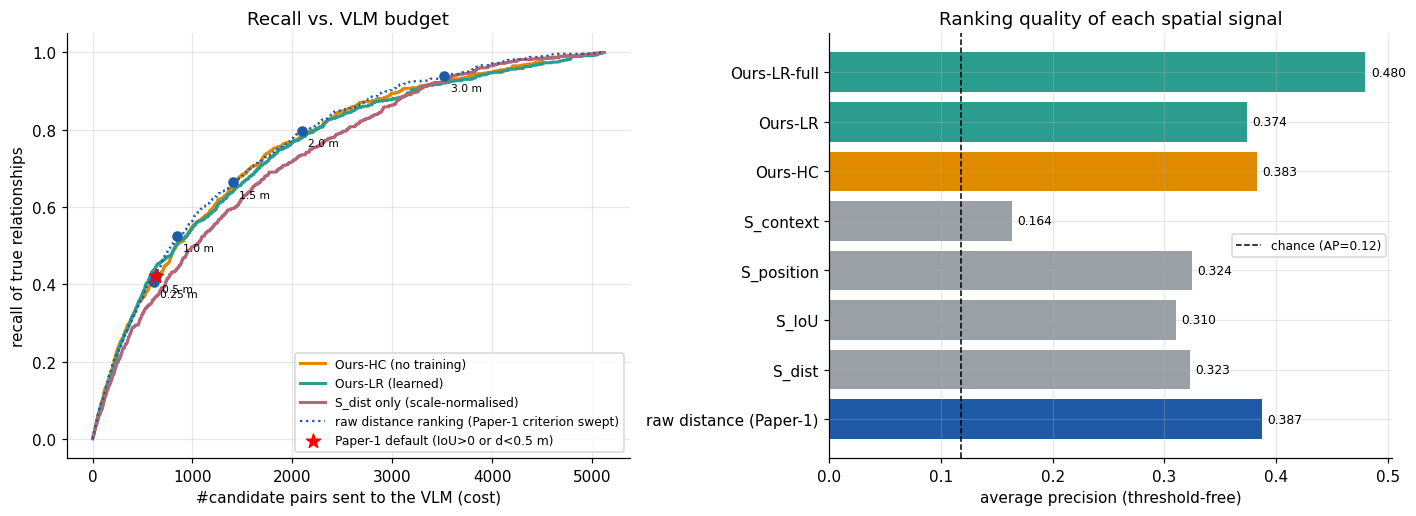

                 score  AUROC    AP
raw distance (Paper-1)  0.800 0.387
                S_dist  0.761 0.323
                 S_IoU  0.773 0.310
            S_position  0.791 0.324
             S_context  0.603 0.164
               Ours-HC  0.789 0.383
               Ours-LR  0.784 0.374
          Ours-LR-full  0.841 0.480

VLM calls needed to reach a target recall (total pairs = 5121 )
       score  pairs@R=0.5  pairs@R=0.7  pairs@R=0.8  pairs@R=0.9
raw distance          784         1580         2147         2972
     Ours-HC          839         1579         2241         3082
     Ours-LR          828         1659         2228         3194
Ours-LR-full          583         1222         1785         2505


In [9]:
if len(PAIRS):
    g = PAIRS.reset_index(drop=True); ytrue = g.y.values
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for col, lab, c in [("score_HC", "Ours-HC (no training)", C_OURS), ("score_LR", "Ours-LR (learned)", C_ALT),
                        ("S_dist", "S_dist only (scale-normalised)", "#b56576")]:
        order = np.argsort(-g[col].values); rec = np.cumsum(ytrue[order]) / ytrue.sum()
        ax[0].plot(np.arange(1, len(g)+1), rec, color=c, lw=2, label=lab)
    order = np.argsort(g.d.values); rec = np.cumsum(ytrue[order]) / ytrue.sum()
    ax[0].plot(np.arange(1, len(g)+1), rec, color=C_PAPER, lw=1.5, ls=":", label="raw distance ranking (Paper-1 criterion swept)")
    for dth in [0.25, 0.5, 1.0, 1.5, 2.0, 3.0]:
        m = paper_filter(g, 1, 1, dth); r = prf(g, m)
        ax[0].scatter(r["pairs"], r["recall"], color=C_PAPER, zorder=5, s=35)
        ax[0].annotate(f"{dth} m", (r["pairs"], r["recall"]), fontsize=7, xytext=(4, -10), textcoords="offset points")
    r = prf(g, paper_filter(g)); ax[0].scatter(r["pairs"], r["recall"], color="red", s=90, marker="*", zorder=6, label="Paper-1 default (IoU>0 or d<0.5 m)")
    ax[0].set_xlabel("#candidate pairs sent to the VLM (cost)"); ax[0].set_ylabel("recall of true relationships")
    ax[0].set_title("Recall vs. VLM budget"); ax[0].legend(fontsize=8, loc="lower right")

    rank_rows = []
    for col, lab in [("d", "raw distance (Paper-1)"), ("S_dist", "S_dist"), ("S_IoU", "S_IoU"), ("S_position", "S_position"),
                     ("S_context", "S_context"), ("score_HC", "Ours-HC"), ("score_LR", "Ours-LR"), ("score_LRfull", "Ours-LR-full")]:
        sc = -g[col].values if col == "d" else g[col].values
        ok = ~np.isnan(sc)
        rank_rows.append(dict(score=lab, AUROC=roc_auc_score(ytrue[ok], sc[ok]), AP=average_precision_score(ytrue[ok], sc[ok])))
    TAB_B2 = pd.DataFrame(rank_rows)
    ax[1].barh(TAB_B2.score, TAB_B2.AP, color=[C_PAPER] + [C_GREY]*4 + [C_OURS, C_ALT, C_ALT])
    ax[1].axvline(ytrue.mean(), color="k", ls="--", lw=1, label=f"chance (AP={ytrue.mean():.2f})")
    for yv, v in enumerate(TAB_B2.AP): ax[1].text(v + .005, yv, f"{v:.3f}", va="center", fontsize=8)
    ax[1].set_xlabel("average precision (threshold-free)"); ax[1].set_title("Ranking quality of each spatial signal"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/figB2_recall_budget.png", bbox_inches="tight"); plt.show()
    print(TAB_B2.round(3).to_string(index=False)); TAB_B2.to_csv(f"{OUT}/tableB2_ranking_quality.csv", index=False)

    # budget needed to reach a target recall
    need = []
    for col, lab in [("d", "raw distance"), ("score_HC", "Ours-HC"), ("score_LR", "Ours-LR"), ("score_LRfull", "Ours-LR-full")]:
        sc = -g[col].values if col == "d" else g[col].values
        rec = np.cumsum(ytrue[np.argsort(-sc)]) / ytrue.sum()
        need.append({"score": lab, **{f"pairs@R={t}": int(np.searchsorted(rec, t) + 1) for t in (0.5, 0.7, 0.8, 0.9)}})
    TAB_B2b = pd.DataFrame(need); print("\nVLM calls needed to reach a target recall (total pairs =", len(g), ")"); print(TAB_B2b.to_string(index=False))
    TAB_B2b.to_csv(f"{OUT}/tableB2b_budget_to_recall.csv", index=False)

### B.3 Per-relation-category recall at Paper-1's budget

budget = 636 pairs (Paper-1's own count)

method           Paper-1 (IoU OR d<0.5)  Ours-HC  Ours-LR  Ours-LR-full
category                                                               
any local                         0.421    0.416    0.447         0.528
directional                       0.216    0.207    0.266         0.402
proximity                         0.884    0.860    0.802         0.760
support/contact                   0.973    0.973    0.932         0.898


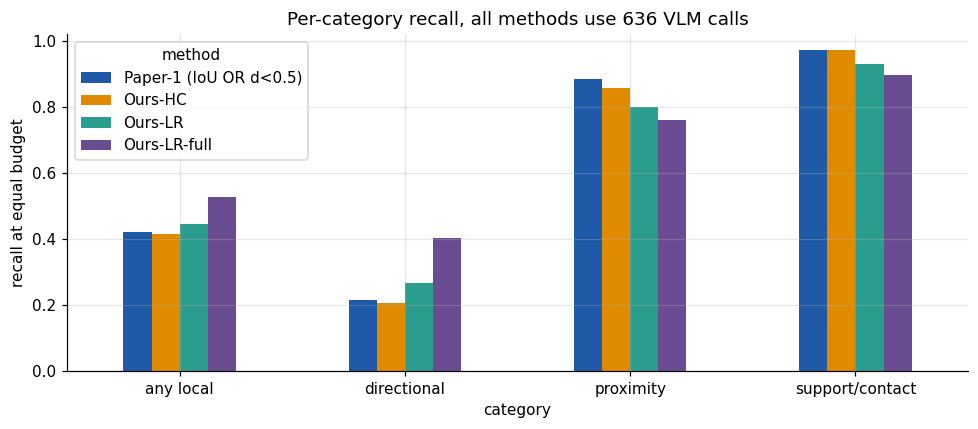

In [10]:
if len(PAIRS):
    g = PAIRS.reset_index(drop=True); n = int(paper_filter(g).sum())
    masks = {"Paper-1 (IoU OR d<0.5)": paper_filter(g), "Ours-HC": at_budget(g, g.score_HC.values, n), "Ours-LR": at_budget(g, g.score_LR.values, n),
             "Ours-LR-full": at_budget(g, g.score_LRfull.values, n)}
    cat_rows = []
    for cat, yc in [("support/contact", "y_support"), ("proximity", "y_proximity"), ("directional", "y_directional"), ("any local", "y")]:
        for name, m in masks.items():
            cat_rows.append(dict(category=cat, method=name, positives=int(g[yc].sum()), recall=prf(g, m, yc)["recall"]))
    TAB_B3 = pd.DataFrame(cat_rows)
    piv = TAB_B3.pivot(index="category", columns="method", values="recall")[list(masks)]
    print(f"budget = {n} pairs (Paper-1's own count)\n"); print(piv.round(3).to_string())
    ax = piv.plot.bar(figsize=(9, 4), color=[C_PAPER, C_OURS, C_ALT, "#6a4c93"], rot=0)
    ax.set_ylabel("recall at equal budget"); ax.set_title(f"Per-category recall, all methods use {n} VLM calls")
    plt.tight_layout(); plt.savefig(f"{OUT}/figB3_category_recall.png", bbox_inches="tight"); plt.show()
    TAB_B3.to_csv(f"{OUT}/tableB3_category_recall.csv", index=False)

### B.4 Generalisation across scale — the limitation Paper-1 states in its own conclusion
*"fixed thresholds (e.g. 0.5 m) may not generalize across varied scene densities or object scales."*
We rescale the whole scene (0.5×–2×: small apartments vs. large halls, or a unit / calibration change).
Ours uses **one** score threshold chosen at scale 1 and is never re-tuned (Ours-LR-full is fitted once at scale 1;
the point of this test is invariance, not accuracy, so its scale-1 row is in-sample).

 scale  paper_pairs  paper_recall  paper_f1  oursHC_pairs  oursHC_recall  oursLRfull_pairs  oursLRfull_recall
  0.50          846         0.525     0.437           635          0.416               636              0.531
  0.67          698         0.457     0.424           635          0.416               636              0.531
  0.80          665         0.439     0.418           635          0.416               636              0.531
  1.00          636         0.421     0.410           636          0.416               636              0.531
  1.25          623         0.412     0.406           636          0.416               635              0.531
  1.50          614         0.407     0.404           636          0.416               635              0.531
  2.00          613         0.407     0.404           636          0.416               635              0.531


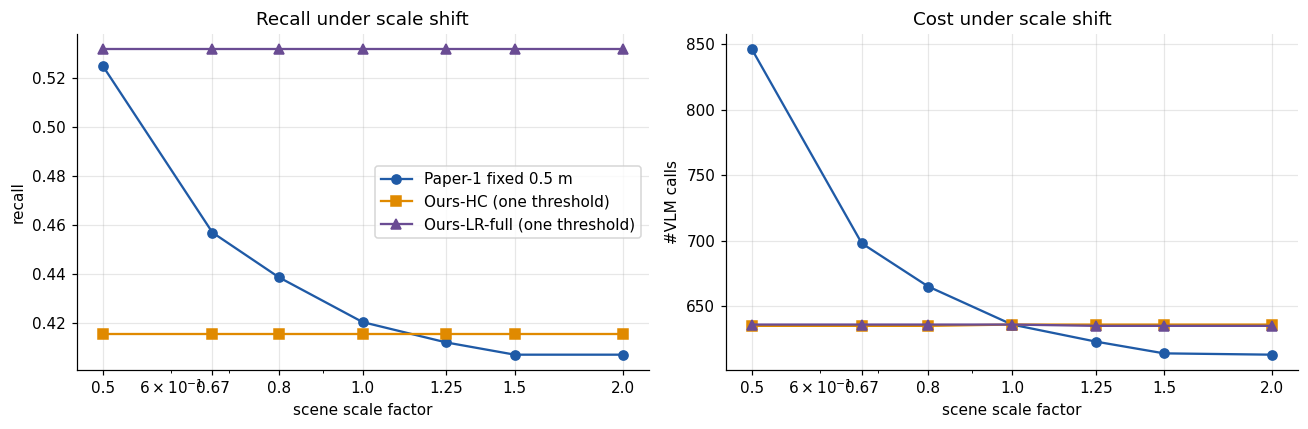

In [11]:
if len(PAIRS):
    SCALES = [0.5, 0.67, 0.8, 1.0, 1.25, 1.5, 2.0]
    base = PAIRS.reset_index(drop=True); n0 = int(paper_filter(base).sum())
    thr_hc = np.sort(base.score_HC.values)[::-1][n0-1]
    LRF = LogisticRegression(max_iter=2000, class_weight="balanced").fit(base[RAW], base.y)
    thr_lr = np.sort(LRF.predict_proba(base[RAW])[:, 1])[::-1][n0-1]
    sc_rows = []
    for s in SCALES:
        g = pd.concat([pair_table(sid, scale=s) for sid in GEO], ignore_index=True)
        rp = prf(g, paper_filter(g)); ro = prf(g, hc_score(g) >= thr_hc - 1e-12)
        rl_ = prf(g, LRF.predict_proba(g[RAW])[:, 1] >= thr_lr - 1e-12)
        sc_rows.append(dict(scale=s, paper_pairs=rp["pairs"], paper_recall=rp["recall"], paper_f1=rp["f1"],
                            oursHC_pairs=ro["pairs"], oursHC_recall=ro["recall"], oursLRfull_pairs=rl_["pairs"], oursLRfull_recall=rl_["recall"]))
    TAB_B4 = pd.DataFrame(sc_rows); print(TAB_B4.round(3).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(SCALES, TAB_B4.paper_recall, "o-", color=C_PAPER, label="Paper-1 fixed 0.5 m"); ax[0].plot(SCALES, TAB_B4.oursHC_recall, "s-", color=C_OURS, label="Ours-HC (one threshold)"); ax[0].plot(SCALES, TAB_B4.oursLRfull_recall, "^-", color="#6a4c93", label="Ours-LR-full (one threshold)")
    ax[0].set_xscale("log"); ax[0].set_xticks(SCALES); ax[0].set_xticklabels(SCALES); ax[0].set_xlabel("scene scale factor"); ax[0].set_ylabel("recall"); ax[0].legend(); ax[0].set_title("Recall under scale shift")
    ax[1].plot(SCALES, TAB_B4.paper_pairs, "o-", color=C_PAPER); ax[1].plot(SCALES, TAB_B4.oursHC_pairs, "s-", color=C_OURS); ax[1].plot(SCALES, TAB_B4.oursLRfull_pairs, "^-", color="#6a4c93")
    ax[1].set_xscale("log"); ax[1].set_xticks(SCALES); ax[1].set_xticklabels(SCALES); ax[1].set_xlabel("scene scale factor"); ax[1].set_ylabel("#VLM calls"); ax[1].set_title("Cost under scale shift")
    plt.tight_layout(); plt.savefig(f"{OUT}/figB4_scale_shift.png", bbox_inches="tight"); plt.show()
    TAB_B4.to_csv(f"{OUT}/tableB4_scale_shift.csv", index=False)

### B.5 Ablation of the composite score (leave-one-term-out, hand-crafted weights, same budget)

In [12]:
if len(PAIRS):
    g = PAIRS.reset_index(drop=True); n = int(paper_filter(g).sum()); ab = []
    for drop in [None] + TERMS:
        keep = [t for t in TERMS if t != drop]; sc = g[keep].mean(1).values
        r = prf(g, at_budget(g, sc, n))
        ab.append(dict(variant="full composite" if drop is None else f"w/o {drop}", recall=r["recall"], precision=r["precision"],
                       f1=r["f1"], AP=average_precision_score(g.y, sc)))
    for t in TERMS:
        r = prf(g, at_budget(g, g[t].values, n)); ab.append(dict(variant=f"{t} alone", recall=r["recall"], precision=r["precision"], f1=r["f1"], AP=average_precision_score(g.y, g[t])))
    TAB_B5 = pd.DataFrame(ab); print(f"budget = {n} pairs\n"); print(TAB_B5.round(3).to_string(index=False))
    TAB_B5.to_csv(f"{OUT}/tableB5_term_ablation.csv", index=False)

budget = 636 pairs

         variant  recall  precision    f1    AP
  full composite   0.416      0.395 0.405 0.383
      w/o S_dist   0.419      0.398 0.408 0.382
       w/o S_IoU   0.424      0.403 0.413 0.385
  w/o S_position   0.412      0.392 0.402 0.379
   w/o S_context   0.409      0.388 0.398 0.346
    S_dist alone   0.369      0.351 0.360 0.323
     S_IoU alone   0.414      0.393 0.403 0.310
S_position alone   0.411      0.390 0.400 0.324
 S_context alone   0.184      0.175 0.179 0.164


### B.6 The same comparison on *reconstructed* geometry (Part A boxes instead of GT boxes)

In [13]:
if STAGE1 and len(PAIRS):
    sid = STAGE1_SCANS[0]; _, dfA, rb, rl, _, _ = STAGE1[sid]
    # map each reconstructed track to its GT object id so GT relationships can be used as labels
    gtid = dict(zip(dfA.track, dfA.gt_id)); boxes_r = {gtid[k]: b for k, b in rb.items() if k in gtid}
    labels_r = {gtid[k]: rl[k] for k in rb if k in gtid}
    gr = pair_table(sid, boxes=boxes_r, labels=labels_r).reset_index(drop=True)
    n = int(paper_filter(gr).sum())
    B6 = [dict(geometry="reconstructed (Part A)", method="Paper-1 (IoU OR d<0.5)", **prf(gr, paper_filter(gr))),
          dict(geometry="reconstructed (Part A)", method="Ours-HC @ same budget", **prf(gr, at_budget(gr, hc_score(gr), n))),
          dict(geometry="reconstructed (Part A)", method="Ours-LR-full @ same budget (object-grouped CV)", **prf(gr, at_budget(gr, oos_scores(gr, RAW)[0], n)))]
    TAB_B6 = pd.DataFrame(B6); print(TAB_B6.round(3).to_string(index=False)); TAB_B6.to_csv(f"{OUT}/tableB6_reconstructed_geometry.csv", index=False)

### B.7 (optional) Fixed-distance recall on your 11-scene distance analysis
Uses `multi_scene_results/all_scene_pairs.csv` produced earlier by `multi_scene_distance_analysis.py` (centroid distance only, all predicates).

In [14]:
if PAIR_CSV:
    ap = pd.read_csv(PAIR_CSV)
    r11 = []
    for dth in [0.5, 1.0, 1.5, 2.0]:
        for sc, g in ap.groupby("scan_id"):
            m = g.distance_m < dth; y = g.has_relationship == 1
            r11.append(dict(threshold=dth, scan=sc, recall=(m & y).sum() / max(y.sum(), 1), precision=(m & y).sum() / max(m.sum(), 1)))
    T11 = pd.DataFrame(r11).groupby("threshold").agg(scans=("scan", "nunique"), recall_mean=("recall", "mean"), recall_min=("recall", "min"),
                                                     recall_max=("recall", "max"), precision_mean=("precision", "mean")).reset_index()
    print(T11.round(3).to_string(index=False)); T11.to_csv(f"{OUT}/tableB7_fixed_distance_11_scenes.csv", index=False)

 threshold  scans  recall_mean  recall_min  recall_max  precision_mean
       0.5     11        0.075       0.030       0.149           0.644
       1.0     11        0.228       0.067       0.426           0.514
       1.5     11        0.432       0.183       0.894           0.442
       2.0     11        0.617       0.333       1.000           0.392


---
# Part C · Retrieval: Paper-1 label-chunk RAG vs. our topology-aware multi-hop retrieval
### C.0 The benchmark (the dataset you asked for) — `3DSSG-MultiHopQA`
Built automatically from the ground-truth 3DSSG graphs, so every answer **and the exact evidence needed** is known by construction.

| type | example | reproduces |
|---|---|---|
| quantity | *how many chair are there in the room?* | Paper-1 Task I (quantity queries) |
| attribute | *what color is the sofa?* | Paper-1 Task I (object-attribute queries) |
| 1-hop | *what is standing on the table?* | Paper-1 Task I (spatial-relationship queries) |
| 2-hop | *what is lying on the object that is standing on the table?* | **our target** |
| 3-hop | *what is close to the object that is lying on the object that is attached to the wall?* | **our target** |

Relational questions come in two phrasings: **canonical** (predicate words as annotated) and **paraphrased**
(`resting on top of`, `near`, `fixed onto` …) to test that retrieval does not rely on exact word overlap.

**Evaluation is reader-agnostic.** We cannot run Qwen-2-72B on Kaggle, so we measure what any reader could possibly answer:
the gold program is executed **only on the retrieved context**. `Answerable` = it returns exactly the gold answer
(the accuracy ceiling for an LLM reading that context). We also report evidence recall, context size (facts / tokens) and latency.

In [15]:
SURF = {"supported by": "supported by", "attached to": "attached to", "standing on": "standing on", "lying on": "lying on",
        "hanging on": "hanging on", "connected to": "connected to", "leaning against": "leaning against", "part of": "part of",
        "belonging to": "belonging to", "build in": "built into", "standing in": "standing in", "cover": "covering",
        "lying in": "lying in", "hanging in": "hanging in", "inside": "inside", "close by": "close to",
        "left": "to the left of", "right": "to the right of", "front": "in front of", "behind": "behind"}
PARA = {"supported by": "held up by", "attached to": "fixed onto", "standing on": "resting on top of", "lying on": "laid on",
        "hanging on": "hung on", "connected to": "joined to", "leaning against": "propped against", "part of": "a component of",
        "belonging to": "owned by", "build in": "built inside", "standing in": "placed inside", "cover": "covering up",
        "lying in": "laid inside", "hanging in": "hung inside", "inside": "within", "close by": "near",
        "left": "on the left side of", "right": "on the right side of", "front": "ahead of", "behind": "at the back of"}

def attr_text(a):
    return "; ".join(f"{k}: {', '.join(v)}" for k, v in sorted(a.items()) if v and k in ("color", "shape", "material", "size", "state", "texture"))

class SceneKB:
    """One scan's scene graph as retrievable facts. Node fact ('N', id) and relation fact ('E', a, p, b)."""
    def __init__(self, sid):
        S = SCENES[sid]; self.sid = sid
        self.lab = {i: l for i, l in S["labels"].items() if l not in BACKGROUND}
        self.attrs = {i: S["attrs"].get(i, {}) for i in self.lab}
        self.E = [(a, b, p) for a, b, p in S["edges"] if a in self.lab and b in self.lab and p in QA_PREDS]
        self.inE = defaultdict(list); self.deg = Counter()
        for a, b, p in self.E:
            self.inE[b].append((a, p)); self.deg[a] += 1; self.deg[b] += 1
        self.facts = [("N", i) for i in self.lab] + [("E", a, p, b) for a, b, p in self.E]
        self.fidx = {f: k for k, f in enumerate(self.facts)}
        self.by_label = defaultdict(list)
        for i, l in self.lab.items(): self.by_label[l].append(i)
        # Paper-1 label-centred chunks (Appendix A format): all instances of a label + their relationships
        self.chunks = []
        for l, ids in self.by_label.items():
            fs = [("N", i) for i in ids] + [("E", a, p, b) for a, b, p in self.E if a in ids or b in ids]
            self.chunks.append((l, fs))
    def render(self, f):
        if f[0] == "N":
            i = f[1]; at = attr_text(self.attrs[i]); return f"{self.lab[i]} {i}" + (f" ({at})" if at else "")
        _, a, p, b = f; return f"{self.lab[a]} {a} {SURF[p]} {self.lab[b]} {b}"
    def chunk_text(self, l, fs):
        return f"object: {l}. number: {len(self.by_label[l])}. " + ". ".join(self.render(f) for f in fs)

def gen_questions(kb, rng, n_per=QA_PER_TYPE):
    Q, seen = [], set()
    lab_cnt = Counter(kb.lab.values()); uniq = [i for i, l in kb.lab.items() if lab_cnt[l] == 1]
    # quantity
    labs = [l for l, c in lab_cnt.items() if 1 <= c <= 6]; rng.shuffle(labs)
    for l in labs[:n_per]:
        Q.append(dict(type="quantity", hops=0, phr="canonical", q=f"how many {l} are there in the room?", label=l,
                      gold=lab_cnt[l], gold_facts=[("N", i) for i in kb.by_label[l]]))
    # attribute
    cand = [i for i in uniq if kb.attrs[i].get("color")]; rng.shuffle(cand)
    for i in cand[:n_per]:
        Q.append(dict(type="attribute", hops=0, phr="canonical", q=f"what color is the {kb.lab[i]}?", label=kb.lab[i],
                      gold=frozenset(kb.attrs[i]["color"]), gold_facts=[("N", i)]))
    # relational h-hop chains: answer -p1-> x1 -p2-> ... -ph-> anchor
    for h in (1, 2, 3):
        made, tries = 0, 0
        while made < n_per and tries < 300:
            tries += 1
            anchors = [i for i in uniq if kb.inE[i]]
            if not anchors: break
            a = anchors[rng.integers(len(anchors))]; cur, path_nodes, preds_from_anchor = a, {a}, []
            ok = True
            for _ in range(h):
                opts = [(u, p) for u, p in kb.inE[cur] if u not in path_nodes]
                if not opts: ok = False; break
                u, p = opts[rng.integers(len(opts))]; preds_from_anchor.append(p); path_nodes.add(u); cur = u
            if not ok: continue
            chain = preds_from_anchor[::-1]                                  # [p1 .. ph]
            layers = [{a}]
            for p in preds_from_anchor:
                layers.append({u for v in layers[-1] for u, pp in kb.inE[v] if pp == p})
            ans_nodes = layers[-1]; ans = frozenset(kb.lab[x] for x in ans_nodes)
            if not (1 <= len(ans) <= 3) or any(len(L) > 6 for L in layers) or ans == {kb.lab[a]}: continue
            need, gold_f = ans_nodes, set()                                    # minimal evidence: back-prune dead ends
            for k in range(h, 0, -1):
                p = preds_from_anchor[k-1]; prev = set()
                for v in layers[k-1]:
                    for u, pp in kb.inE[v]:
                        if pp == p and u in need: gold_f.add(("E", u, p, v)); prev.add(v)
                need = prev
            for phr, table in (("canonical", SURF), ("paraphrased", PARA)):
                q = "what is " + " the object that is ".join(table[p] for p in chain) + f" the {kb.lab[a]}?"
                if q in seen: continue
                seen.add(q)
                Q.append(dict(type=f"{h}-hop", hops=h, phr=phr, q=q, label=kb.lab[a], chain=chain, anchor=a, gold=ans,
                              gold_facts=sorted(gold_f)))
            made += 1
    for x in Q: x["scan"] = kb.sid
    return Q

rng = np.random.default_rng(SEED)
QA_SCANS = sorted(SCENES)
QA_SCANS = [QA_SCANS[i] for i in rng.permutation(len(QA_SCANS))[:N_QA_SCANS]]
for sid in GEO:                                   # always include geometry scans (needed in Part D)
    if sid not in QA_SCANS: QA_SCANS.append(sid)
KB = {sid: SceneKB(sid) for sid in QA_SCANS}
QA = [q for sid in QA_SCANS for q in gen_questions(KB[sid], rng)]
split_perm = rng.permutation(len(QA_SCANS)); nt = len(QA_SCANS)
SPLIT = {}
for r, k in enumerate(split_perm):
    SPLIT[QA_SCANS[k]] = "train" if r < 0.6*nt else ("val" if r < 0.8*nt else "test")
for x in QA: x["split"] = SPLIT[x["scan"]]
QA_DF = pd.DataFrame([{k: v for k, v in x.items() if k not in ("gold_facts",)} for x in QA])
print(f"questions: {len(QA)} from {len(QA_SCANS)} scans")
print(QA_DF.groupby(["type", "phr"]).size().unstack(fill_value=0))
print("\nsplit (scene-level):", Counter(SPLIT.values()))
for t in ["quantity", "attribute", "1-hop", "2-hop", "3-hop"]:
    ex = next(x for x in QA if x["type"] == t)
    print(f"  [{t}] {ex['q']}  ->  {sorted(ex['gold']) if not isinstance(ex['gold'], int) else ex['gold']}")
with open(f"{OUT}/3dssg_multihop_qa.json", "w") as f:
    json.dump([{**{k: (sorted(v) if isinstance(v, frozenset) else v) for k, v in x.items() if k not in ("gold_facts",)},
                "gold_evidence": [KB[x['scan']].render(ff) for ff in x["gold_facts"]]} for x in QA], f, indent=1, default=int)
print("saved benchmark ->", f"{OUT}/3dssg_multihop_qa.json")

questions: 10679 from 405 scans
phr        canonical  paraphrased
type                             
1-hop           1331         1331
2-hop           1402         1402
3-hop           1383         1383
attribute        851            0
quantity        1596            0

split (scene-level): Counter({'train': 243, 'val': 81, 'test': 81})
  [quantity] how many radiator are there in the room?  ->  1
  [attribute] what color is the bed?  ->  ['blue', 'bright']
  [1-hop] what is to the right of the curtain?  ->  ['radiator', 'window']
  [2-hop] what is to the left of the object that is to the left of the radiator?  ->  ['curtain']
  [3-hop] what is covering the object that is behind the object that is to the left of the radiator?  ->  ['blinds']
saved benchmark -> /kaggle/working/3dssg_multihop_qa.json


### C.1 Retrievers
* **Paper-1 (reproduced, Eq. 22–26)**: one chunk per object label (all instances + their relations, Appendix-A format),
  encoded with a text encoder (TF-IDF here instead of CLIP/BERT, identical for every method), top-k cosine search.
* **Triple-RAG**: a common stronger baseline — every fact is its own vector, top-K facts.
* **Ours**: (1) query decomposition into anchor + ordered relation hops; (2) semantic anchor grounding;
  (3) hop-by-hop traversal on graph edges with edge score `α·Semantic(pred, hop) + γ·Topology − λ·PathCost`;
  if the best predicate match of a hop is below a confidence `κ`, that hop falls back to topology-only expansion
  (confidence-aware traversal — Paper-1's own suggested future direction);
  (4) path ranking with beam `B`; (5) compact subgraph = only facts on complete anchor→answer paths.

In [16]:
ALL_DOCS = []
for kb in KB.values():
    ALL_DOCS += [kb.chunk_text(l, fs) for l, fs in kb.chunks] + [kb.render(f) for f in kb.facts]
ENC = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1).fit(ALL_DOCS + [x["q"] for x in QA if x["split"] == "train"])
PRED_ENC = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)).fit(list(SURF.values()))
PRED_NAMES = list(SURF); PRED_MAT = PRED_ENC.transform([SURF[p] for p in PRED_NAMES])
for kb in KB.values():
    kb.chunk_mat = ENC.transform([kb.chunk_text(l, fs) for l, fs in kb.chunks])
    kb.fact_mat = ENC.transform([kb.render(f) for f in kb.facts])
    kb.lab_list = sorted(kb.by_label)

def cos_top(mat, qv, k):
    s = (mat @ qv.T).toarray().ravel(); return np.argsort(-s)[:k]

def retrieve_paper1(kb, q, k=PAPER_TOPK):
    idx = cos_top(kb.chunk_mat, ENC.transform([q]), k)
    ctx = []
    for i in idx: ctx += kb.chunks[i][1]
    return list(dict.fromkeys(ctx))

def retrieve_triple(kb, q, k=15):
    idx = cos_top(kb.fact_mat, ENC.transform([q]), k); return [kb.facts[i] for i in idx]

def decompose(q):
    """Rule-based decomposition (stand-in for an LLM decomposer): returns (type, anchor_text, [hop predicate texts p1..ph])."""
    q = q.lower().strip().rstrip("?")
    if q.startswith("how many "): return "quantity", q[9:].split(" are there")[0], []
    if q.startswith("what color is the "): return "attribute", q[18:], []
    body = q[len("what is "):]; segs = body.split(" the object that is ")
    last_pred, anchor = segs[-1].rsplit(" the ", 1)
    return "relational", anchor, segs[:-1] + [last_pred]

def ground_anchor(kb, text):
    if text in kb.by_label: return list(kb.by_label[text])
    sims = (ENC.transform(kb.lab_list) @ ENC.transform([text]).T).toarray().ravel()
    return list(kb.by_label[kb.lab_list[int(np.argmax(sims))]]) if sims.max() > 0.5 else []

def pred_sims(text):
    return dict(zip(PRED_NAMES, (PRED_MAT @ PRED_ENC.transform([text]).T).toarray().ravel()))

QMAP = {(x["scan"], x["q"]): x for x in QA}

def retrieve_ours(kb, q, beam=10, tau=0.9, alpha=1.0, gamma=0.3, lam=0.05, guided=True, spatial=None, beta=0.0,
                  max_facts=60, oracle_decomp=False, kappa=0.0):
    typ, anchor_txt, hops = decompose(q)
    if oracle_decomp and typ == "relational":                     # upper bound: a perfect (e.g. LLM) decomposer
        hops = QMAP[(kb.sid, q)]["chain"]
    anchors = ground_anchor(kb, anchor_txt)
    if typ in ("quantity", "attribute"): return [("N", i) for i in anchors]
    frontier, layers = set(anchors), []
    for k, ptxt in enumerate(reversed(hops)):                      # expand from the anchor outwards (ph first)
        sim = {p: float(p == ptxt) for p in PRED_NAMES} if oracle_decomp else pred_sims(ptxt)
        best = max(sim.values())
        hop_guided = guided and best >= kappa                      # confidence-aware: fall back to topology when unsure
        cand = []
        for v in frontier:
            for u, p in kb.inE[v]:
                s_sem = sim[p] if hop_guided else 0.0
                if hop_guided and s_sem < tau * best: continue       # keep predicates that match this hop
                topo = 1.0 / math.log(2 + kb.deg[u])                  # penalise hub nodes (walls, floors)
                s_sp = spatial(u, v) if spatial is not None else 0.0
                cand.append((alpha*s_sem + beta*s_sp + gamma*topo - lam*k, u, p, v))
        cand.sort(key=lambda x: -x[0]); cand = cand[:beam]
        layers.append(cand); frontier = {u for _, u, _, _ in cand}
        if not frontier: break
    # compact subgraph: keep only edges on complete anchor->answer paths (back-prune dead ends)
    need, keep = frontier, []
    for cand in reversed(layers):
        prev = set()
        for _, u, p, v in cand:
            if u in need: keep.append(("E", u, p, v)); prev.add(v)
        need = prev
    return ([("N", i) for i in anchors] + keep)[:max_facts]

def retrieve_ego(kb, q):
    """Ablation: anchor 1-hop ego graph (no multi-hop traversal)."""
    _, anchor_txt, _ = decompose(q); A = set(ground_anchor(kb, anchor_txt))
    return [("N", i) for i in A] + [("E", a, p, b) for a, b, p in kb.E if a in A or b in A]

def answer_from(kb, x, ctx):
    """Reader-agnostic check: execute the GOLD program only on the retrieved facts."""
    ctxs = set(ctx)
    mentioned = {f[1] for f in ctxs if f[0] == "N"} | {f[1] for f in ctxs if f[0] == "E"} | {f[3] for f in ctxs if f[0] == "E"}
    if x["type"] == "quantity":
        return sum(1 for i in mentioned if kb.lab.get(i) == x["label"]) == x["gold"]
    if x["type"] == "attribute":
        return any(f[0] == "N" and kb.lab[f[1]] == x["label"] for f in ctxs)
    inE = defaultdict(list)
    for f in ctxs:
        if f[0] == "E": inE[f[3]].append((f[1], f[2]))
    F = {i for i in mentioned if kb.lab.get(i) == x["label"]}
    for p in reversed(x["chain"]):
        F = {u for v in F for u, pp in inE[v] if pp == p}
    return frozenset(kb.lab[i] for i in F) == x["gold"]

def evaluate(method_fn, name, questions, **kw):
    rows = []
    for x in questions:
        kb = KB[x["scan"]]; t0 = time.perf_counter(); ctx = method_fn(kb, x["q"], **kw); dt = (time.perf_counter() - t0) * 1000
        gf = set(x["gold_facts"]); cs = set(ctx)
        rows.append(dict(method=name, type=x["type"], hops=x["hops"], phr=x["phr"], split=x["split"], scan=x["scan"],
                         answerable=int(answer_from(kb, x, ctx)), ev_recall=len(gf & cs) / max(len(gf), 1),
                         ev_precision=len(gf & cs) / max(len(cs), 1), facts=len(cs),
                         tokens=int(1.3 * sum(len(kb.render(f).split()) for f in cs)), latency_ms=dt))
    return rows

### C.2 Hyper-parameter tuning of our retriever on **train scans only** (scene-level split)

In [17]:
TRAIN_Q = [x for x in QA if x["split"] == "train" and x["hops"] > 0]
VAL_Q = [x for x in QA if x["split"] == "val" and x["hops"] > 0]
grid = []
for beam in (10, 20, 40):
    for tau in (0.7, 0.8, 0.9):
        for gamma in (0.3,):
            for kappa in (0.0, 0.6, 0.8, 0.95):
                r = pd.DataFrame(evaluate(retrieve_ours, "ours", TRAIN_Q, beam=beam, tau=tau, gamma=gamma, kappa=kappa))
                grid.append(dict(beam=beam, tau=tau, gamma=gamma, kappa=kappa, train_answerable=r.answerable.mean(), train_facts=r.facts.mean()))
GRID = pd.DataFrame(grid)
GRID["objective"] = GRID.train_answerable - 0.001 * GRID.train_facts           # accuracy first, then compactness
GRID = GRID.sort_values("objective", ascending=False)
print(GRID.head(8).round(3).to_string(index=False))
BEST = GRID.iloc[0][["beam", "tau", "gamma", "kappa"]].to_dict(); BEST["beam"] = int(BEST["beam"])
rv = pd.DataFrame(evaluate(retrieve_ours, "ours", VAL_Q, **BEST))
print("\nselected:", BEST, f"| validation answerable = {rv.answerable.mean():.3f}")
GRID.to_csv(f"{OUT}/tableC2_tuning_grid.csv", index=False)

 beam  tau  gamma  kappa  train_answerable  train_facts  objective
   40  0.8    0.3   0.60             0.949       12.365      0.936
   40  0.7    0.3   0.60             0.949       12.366      0.936
   40  0.9    0.3   0.60             0.944       12.333      0.931
   20  0.8    0.3   0.60             0.929       10.653      0.918
   20  0.7    0.3   0.60             0.929       10.655      0.918
   20  0.9    0.3   0.60             0.924       10.621      0.913
   40  0.9    0.3   0.95             0.908       15.585      0.893
   40  0.8    0.3   0.95             0.908       15.592      0.893

selected: {'beam': 40, 'tau': 0.8, 'gamma': 0.3, 'kappa': 0.6} | validation answerable = 0.948


### C.3 Main results on the held-out **test scans**

In [18]:
TEST_Q = [x for x in QA if x["split"] == "test"]
METHODS = [
    ("Paper-1 chunk RAG (k=3)", retrieve_paper1, dict(k=3)),
    ("Paper-1 chunk RAG (k=5)", retrieve_paper1, dict(k=5)),
    ("Paper-1 chunk RAG (k=10)", retrieve_paper1, dict(k=10)),
    ("Triple-RAG (K=15)", retrieve_triple, dict(k=15)),
    ("Triple-RAG (K=50)", retrieve_triple, dict(k=50)),
    ("Ours w/o traversal (anchor ego-graph)", retrieve_ego, {}),
    ("Ours w/o predicate guidance (topology only)", retrieve_ours, dict(beam=BEST["beam"], guided=False, gamma=BEST["gamma"])),
    ("Ours w/o hub penalty (γ=0)", retrieve_ours, dict(beam=BEST["beam"], tau=BEST["tau"], kappa=BEST["kappa"], gamma=0.0)),
    ("Ours w/o confidence fallback (κ=0)", retrieve_ours, dict(beam=BEST["beam"], tau=BEST["tau"], gamma=BEST["gamma"], kappa=0.0)),
    ("Ours (full)", retrieve_ours, dict(**BEST)),
    ("Ours + oracle decomposition (upper bound)", retrieve_ours, dict(**BEST, oracle_decomp=True)),
]
RES = pd.DataFrame([r for name, fn, kw in METHODS for r in evaluate(fn, name, TEST_Q, **kw)])
RES.to_csv(f"{OUT}/raw_results_partC.csv", index=False)
order = [m for m, _, _ in METHODS]
T_main = RES.groupby("method").agg(answerable=("answerable", "mean"), ev_recall=("ev_recall", "mean"), ev_precision=("ev_precision", "mean"),
                                   facts=("facts", "mean"), tokens=("tokens", "mean"), latency_ms=("latency_ms", "mean")).reindex(order)
print(f"test questions: {len(TEST_Q)} from {len({x['scan'] for x in TEST_Q})} unseen scans\n")
print(T_main.round(3).to_string()); T_main.to_csv(f"{OUT}/tableC3_main.csv")

T_type = RES.pivot_table(index="method", columns="type", values="answerable", aggfunc="mean").reindex(order)[["quantity", "attribute", "1-hop", "2-hop", "3-hop"]]
print("\nAnswerable by question type:"); print(T_type.round(3).to_string()); T_type.to_csv(f"{OUT}/tableC3b_by_type.csv")

T_phr = RES[RES.hops > 0].pivot_table(index="method", columns=["phr", "hops"], values="answerable", aggfunc="mean").reindex(order)
print("\nRelational questions: canonical vs paraphrased wording:"); print(T_phr.round(3).to_string()); T_phr.to_csv(f"{OUT}/tableC3c_paraphrase.csv")

test questions: 2139 from 81 unseen scans

                                             answerable  ev_recall  ev_precision    facts    tokens  latency_ms
method                                                                                                         
Paper-1 chunk RAG (k=3)                           0.849      0.915         0.102   41.236   375.226       0.701
Paper-1 chunk RAG (k=5)                           0.947      0.972         0.072   66.966   604.773       0.715
Paper-1 chunk RAG (k=10)                          0.993      0.996         0.050  116.056  1034.324       0.741
Triple-RAG (K=15)                                 0.581      0.721         0.146   14.963   142.968       0.750
Triple-RAG (K=50)                                 0.806      0.894         0.072   46.918   439.957       0.722
Ours w/o traversal (anchor ego-graph)             0.497      0.681         0.221   13.129   119.687       0.011
Ours w/o predicate guidance (topology only)       0.876      

### C.4 Statistical significance (paired bootstrap over test **scans**, 2,000 resamples)

In [19]:
def paired_bootstrap(res, a, b, n=2000, sub=None):
    d = res if sub is None else res[sub(res)]
    A = d[d.method == a].groupby("scan").answerable.mean(); B = d[d.method == b].groupby("scan").answerable.mean()
    sc = A.index.intersection(B.index); diff = (B[sc] - A[sc]).values
    bs = np.array([diff[np.random.default_rng(i).integers(0, len(diff), len(diff))].mean() for i in range(n)])
    return diff.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), (bs <= 0).mean()

sig = []
for ours in ["Ours (full)", "Ours + oracle decomposition (upper bound)"]:
    for base in ["Paper-1 chunk RAG (k=3)", "Triple-RAG (K=50)"]:
        for lab, sub in [("all", None), ("multi-hop, canonical", lambda r: (r.hops >= 2) & (r.phr == "canonical")),
                         ("multi-hop, paraphrased", lambda r: (r.hops >= 2) & (r.phr == "paraphrased"))]:
            m, lo, hi, p = paired_bootstrap(RES, base, ours, sub=sub)
            sig.append(dict(ours=ours, baseline=base, subset=lab, delta_answerable=m, ci95_low=lo, ci95_high=hi, p_value_one_sided=p))
T_sig = pd.DataFrame(sig); print(T_sig.round(3).to_string(index=False)); T_sig.to_csv(f"{OUT}/tableC4_significance.csv", index=False)

                                     ours                baseline                 subset  delta_answerable  ci95_low  ci95_high  p_value_one_sided
                              Ours (full) Paper-1 chunk RAG (k=3)                    all             0.109     0.086      0.133                0.0
                              Ours (full) Paper-1 chunk RAG (k=3)   multi-hop, canonical             0.219     0.170      0.269                0.0
                              Ours (full) Paper-1 chunk RAG (k=3) multi-hop, paraphrased             0.210     0.154      0.265                0.0
                              Ours (full)       Triple-RAG (K=50)                    all             0.148     0.121      0.178                0.0
                              Ours (full)       Triple-RAG (K=50)   multi-hop, canonical             0.229     0.165      0.295                0.0
                              Ours (full)       Triple-RAG (K=50) multi-hop, paraphrased             0.364     0.300  

### C.5 Figures

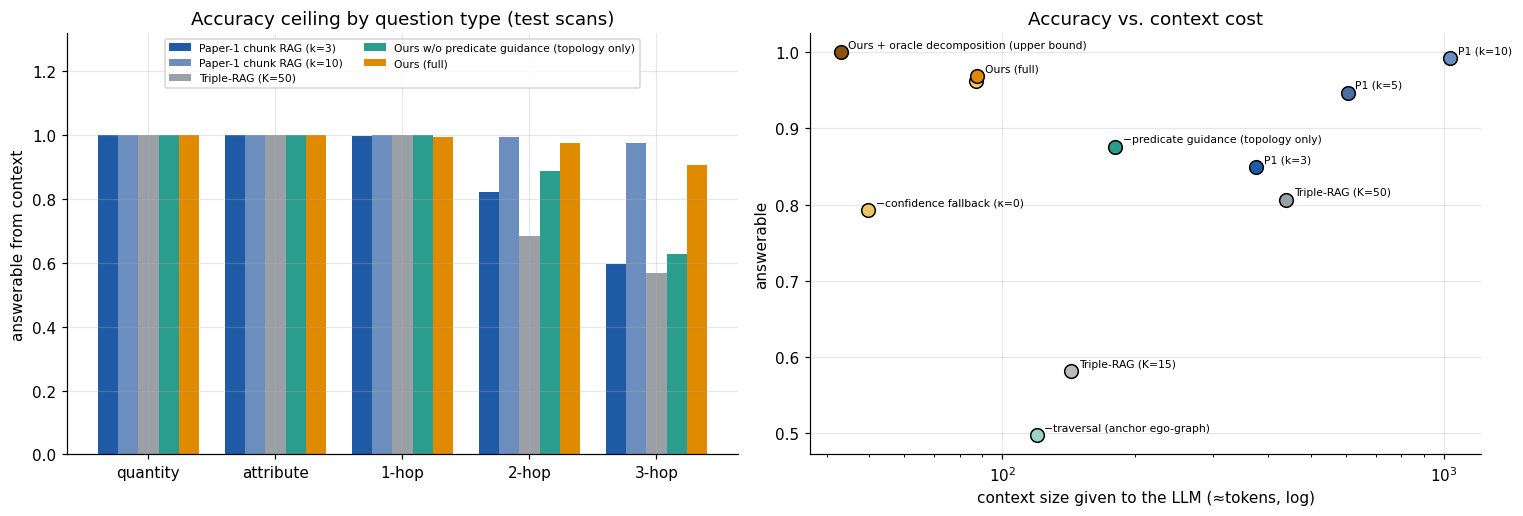

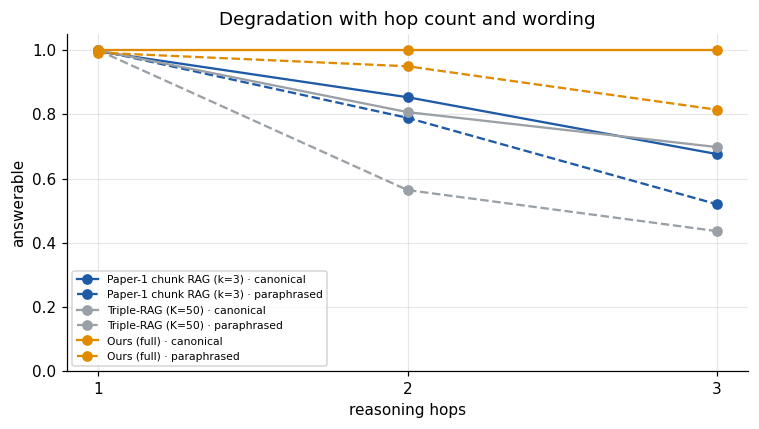

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
show = ["Paper-1 chunk RAG (k=3)", "Paper-1 chunk RAG (k=10)", "Triple-RAG (K=50)", "Ours w/o predicate guidance (topology only)", "Ours (full)"]
cols = [C_PAPER, "#6c8ebf", C_GREY, C_ALT, C_OURS]
x = np.arange(5); w = 0.16
for k, (m, c) in enumerate(zip(show, cols)):
    ax[0].bar(x + (k-2)*w, T_type.loc[m].values, w, color=c, label=m)
ax[0].set_xticks(x); ax[0].set_xticklabels(T_type.columns); ax[0].set_ylabel("answerable from context"); ax[0].set_ylim(0, 1.05)
ax[0].set_ylim(0, 1.32); ax[0].set_title("Accuracy ceiling by question type (test scans)"); ax[0].legend(fontsize=7, loc="upper center", ncol=2)
for m, c in zip(order, [C_PAPER, "#4a6fa5", "#6c8ebf", "#bbbbbb", C_GREY, "#9ad1c9", C_ALT, "#f2c57c", "#e9c46a", C_OURS, "#8c510a"]):
    r = T_main.loc[m]; ax[1].scatter(r.tokens, r.answerable, s=80, color=c, edgecolor="k", zorder=3)
    if "hub" in m: continue
    ax[1].annotate(m.replace("Paper-1 chunk RAG", "P1").replace("Ours w/o ", "−"), (r.tokens, r.answerable), fontsize=7, xytext=(5, 3), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("context size given to the LLM (≈tokens, log)"); ax[1].set_ylabel("answerable")
ax[1].set_title("Accuracy vs. context cost")
plt.tight_layout(); plt.savefig(f"{OUT}/figC5_retrieval.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for m, c in zip(["Paper-1 chunk RAG (k=3)", "Triple-RAG (K=50)", "Ours (full)"], [C_PAPER, C_GREY, C_OURS]):
    for phr, ls in [("canonical", "-"), ("paraphrased", "--")]:
        v = [T_phr.loc[m, (phr, h)] for h in (1, 2, 3)]
        ax.plot([1, 2, 3], v, ls, marker="o", color=c, label=f"{m} · {phr}")
ax.set_xticks([1, 2, 3]); ax.set_xlabel("reasoning hops"); ax.set_ylabel("answerable"); ax.set_ylim(0, 1.05)
ax.set_title("Degradation with hop count and wording"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/figC5b_hops_paraphrase.png", bbox_inches="tight"); plt.show()

### C.6 Equal context budget — what fits in a fixed LLM prompt?
`Answerable` above rewards dumping more of the graph into the prompt. Real LLM readers have limited, noise-sensitive context,
so we truncate every method's **ranked** context to the same token budget and re-evaluate.

Relational test questions (1-3 hop, both phrasings), answerable at a fixed token budget:
budget_tokens                                32     64     128    256    512
method                                                                      
Paper-1 chunk RAG (k=3)                    0.117  0.223  0.417  0.651  0.774
Paper-1 chunk RAG (k=10)                   0.117  0.223  0.419  0.667  0.868
Triple-RAG (K=50)                          0.219  0.319  0.450  0.615  0.747
Ours (full)                                0.355  0.611  0.777  0.889  0.955
Ours + oracle decomposition (upper bound)  0.463  0.797  0.950  0.999  1.000


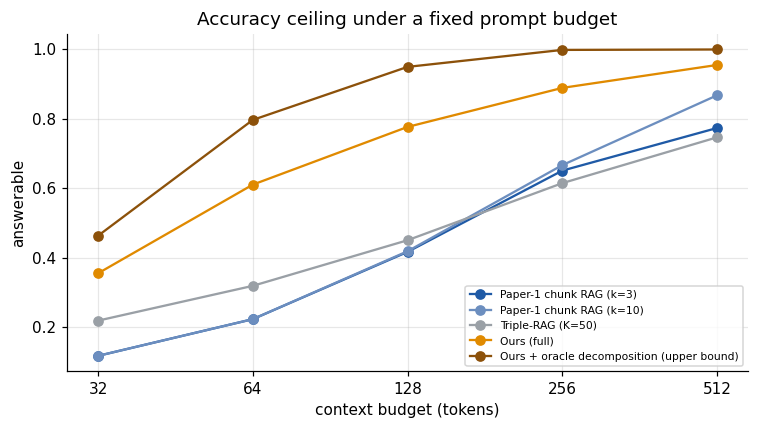

In [21]:
def truncate(kb, ctx, budget):
    out, used = [], 0
    for f in ctx:
        t = int(1.3 * len(kb.render(f).split()))
        if used + t > budget: break
        out.append(f); used += t
    return out

BUDGETS = [32, 64, 128, 256, 512]
bud_methods = [("Paper-1 chunk RAG (k=3)", retrieve_paper1, dict(k=3)), ("Paper-1 chunk RAG (k=10)", retrieve_paper1, dict(k=10)),
               ("Triple-RAG (K=50)", retrieve_triple, dict(k=50)), ("Ours (full)", retrieve_ours, dict(**BEST)),
               ("Ours + oracle decomposition (upper bound)", retrieve_ours, dict(**BEST, oracle_decomp=True))]
REL_TEST = [x for x in TEST_Q if x["hops"] >= 1]
brow = []
for name, fn, kw in bud_methods:
    ctxs = [(x, fn(KB[x["scan"]], x["q"], **kw)) for x in REL_TEST]
    for B in BUDGETS:
        acc = np.mean([answer_from(KB[x["scan"]], x, truncate(KB[x["scan"]], c, B)) for x, c in ctxs])
        brow.append(dict(method=name, budget_tokens=B, answerable=acc))
T_bud = pd.DataFrame(brow).pivot(index="method", columns="budget_tokens", values="answerable").reindex([m for m, _, _ in bud_methods])
print("Relational test questions (1-3 hop, both phrasings), answerable at a fixed token budget:"); print(T_bud.round(3).to_string())
T_bud.to_csv(f"{OUT}/tableC6_token_budget.csv")
fig, ax = plt.subplots(figsize=(7, 4))
for (m, _, _), c in zip(bud_methods, [C_PAPER, "#6c8ebf", C_GREY, C_OURS, "#8c510a"]):
    ax.plot(BUDGETS, T_bud.loc[m].values, "o-", color=c, label=m)
ax.set_xscale("log", base=2); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS); ax.set_xlabel("context budget (tokens)")
ax.set_ylabel("answerable"); ax.set_title("Accuracy ceiling under a fixed prompt budget"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/figC6_token_budget.png", bbox_inches="tight"); plt.show()

### C.7 Scalability — multi-room environments
A single 3RScan room has ~29 objects, so Paper-1's top-3 label chunks already cover a large part of the whole graph.
Real deployments (apartments, offices) are larger. We merge K unseen **test** rooms into one environment
(ids made disjoint), regenerate questions on the merged graph, and re-run every retriever.

 rooms                                    method  questions  objects  answerable  answerable_canonical   tokens  ev_precision  latency_ms
     1                   Paper-1 chunk RAG (k=3)        156   21.833       0.724                 0.795  486.064         0.143       0.730
     1                  Paper-1 chunk RAG (k=10)        156   21.833       1.000                 1.000 1080.769         0.080       0.754
     1                         Triple-RAG (K=50)        156   21.833       0.679                 0.808  421.147         0.105       0.759
     1                               Ours (full)        156   21.833       0.942                 1.000  122.692         0.597       1.605
     1 Ours + oracle decomposition (upper bound)        156   21.833       1.000                 1.000   63.000         0.821       0.029
     2                   Paper-1 chunk RAG (k=3)        188   52.583       0.649                 0.702  465.415         0.113       0.786
     2                  Paper-1 ch

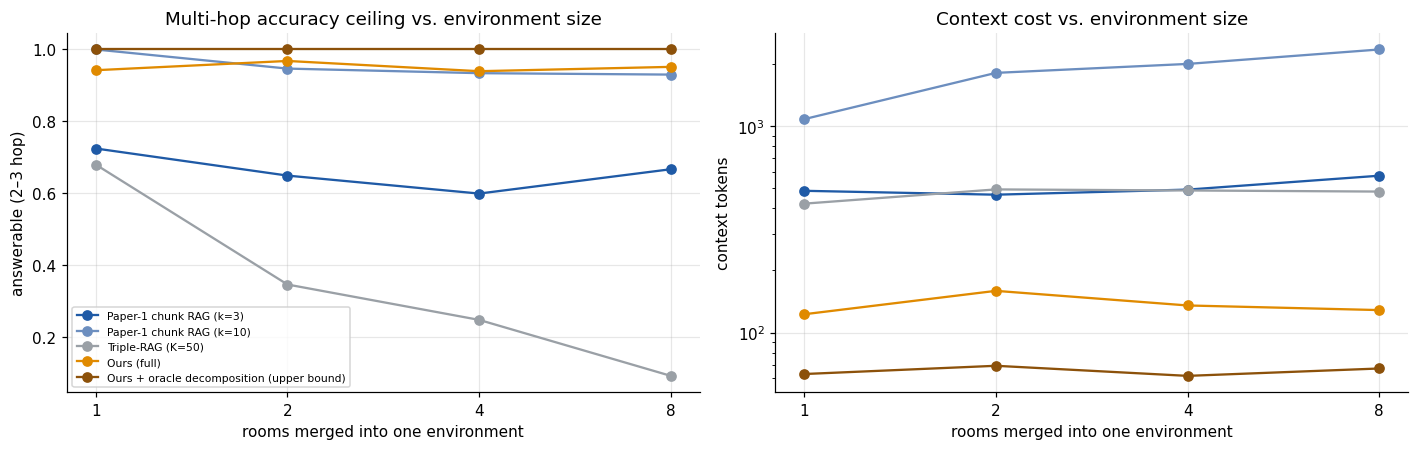

In [22]:
def merged_kb(sids, key):
    labels, attrs, edges = {}, {}, []
    for r, sid in enumerate(sids):
        S = SCENES[sid]; off = (r + 1) * 100000
        labels.update({off + i: l for i, l in S["labels"].items()}); attrs.update({off + i: a for i, a in S["attrs"].items()})
        edges += [(off + a, off + b, p) for a, b, p in S["edges"]]
    SCENES[key] = dict(labels=labels, attrs=attrs, edges=edges)
    kb = SceneKB(key); kb.chunk_mat = ENC.transform([kb.chunk_text(l, fs) for l, fs in kb.chunks])
    kb.fact_mat = ENC.transform([kb.render(f) for f in kb.facts]); kb.lab_list = sorted(kb.by_label); return kb

test_scans = [s for s in QA_SCANS if SPLIT[s] == "test"]
scal = []
rng_s = np.random.default_rng(SEED + 1)
for K in (1, 2, 4, 8):
    qs = []
    for g in range(12):
        sids = list(rng_s.choice(test_scans, K, replace=False)); key = f"merged_K{K}_{g}"
        KB[key] = merged_kb(sids, key)
        new = [x for x in gen_questions(KB[key], rng_s, n_per=4) if x["hops"] >= 2]
        for x in new: x["split"] = "scal"; QMAP[(key, x["q"])] = x
        qs += new
    for name, fn, kw in bud_methods:
        r = pd.DataFrame(evaluate(fn, name, qs, **kw))
        scal.append(dict(rooms=K, method=name, questions=len(qs), objects=np.mean([len(KB[f"merged_K{K}_{g}"].lab) for g in range(12)]),
                         answerable=r.answerable.mean(), answerable_canonical=r[r.phr == "canonical"].answerable.mean(),
                         tokens=r.tokens.mean(), ev_precision=r.ev_precision.mean(), latency_ms=r.latency_ms.mean()))
T_scal = pd.DataFrame(scal); print(T_scal.round(3).to_string(index=False)); T_scal.to_csv(f"{OUT}/tableC7_scalability.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for (m, _, _), c in zip(bud_methods, [C_PAPER, "#6c8ebf", C_GREY, C_OURS, "#8c510a"]):
    d = T_scal[T_scal.method == m]
    ax[0].plot(d.rooms, d.answerable, "o-", color=c, label=m); ax[1].plot(d.rooms, d.tokens, "o-", color=c, label=m)
for a in ax: a.set_xscale("log", base=2); a.set_xticks([1, 2, 4, 8]); a.set_xticklabels([1, 2, 4, 8]); a.set_xlabel("rooms merged into one environment")
ax[0].set_ylabel("answerable (2–3 hop)"); ax[1].set_ylabel("context tokens"); ax[1].set_yscale("log"); ax[0].legend(fontsize=7)
ax[0].set_title("Multi-hop accuracy ceiling vs. environment size"); ax[1].set_title("Context cost vs. environment size")
plt.tight_layout(); plt.savefig(f"{OUT}/figC7_scalability.png", bbox_inches="tight"); plt.show()

---
# Part D · End-to-end: does the spatial filter change downstream multi-hop QA?
For every geometry scan we build the scene graph the way Paper-1 would: **only proposed pairs can become edges**
(their predicate comes from the oracle relation predictor = GT). Questions are generated from the *full* GT graph,
so a missing edge is a real failure. Compared at the **same number of VLM calls**.

In [23]:
E2E = []
if len(PAIRS):
    for sid in GEO:
        g = PAIRS[PAIRS.scan == sid].reset_index(drop=True); n = int(paper_filter(g).sum())
        variants = {"full GT graph (upper bound)": np.ones(len(g), bool), "Paper-1 filter (IoU OR d<0.5)": paper_filter(g),
                    "Ours-HC @ same budget": at_budget(g, g.score_HC.values, n), "Ours-LR-full @ same budget": at_budget(g, g.score_LRfull.values, n)}
        kb_full = KB[sid] if sid in KB else SceneKB(sid)
        qs = [x for x in gen_questions(kb_full, np.random.default_rng(SEED + 7), n_per=25) if x["hops"] >= 1 and x["phr"] == "canonical"]
        for vname, m in variants.items():
            keep = {frozenset((a, b)) for a, b in zip(g.i[m], g.j[m])}
            key = f"{sid}::{vname}"
            SCENES[key] = dict(labels=SCENES[sid]["labels"], attrs=SCENES[sid]["attrs"],
                               edges=[e for e in SCENES[sid]["edges"] if frozenset((e[0], e[1])) in keep])
            kb = SceneKB(key); kb.chunk_mat = ENC.transform([kb.chunk_text(l, fs) for l, fs in kb.chunks])
            kb.fact_mat = ENC.transform([kb.render(f) for f in kb.facts]); kb.lab_list = sorted(kb.by_label); KB[key] = kb
            for x in qs:
                for rname, fn, kw in [("Paper-1 chunk RAG (k=3)", retrieve_paper1, dict(k=3)), ("Ours (full)", retrieve_ours, dict(**BEST))]:
                    ctx = fn(kb, x["q"], **kw)
                    E2E.append(dict(scan=sid, graph=vname, retriever=rname, hops=x["hops"], graph_edges=len(kb.E),
                                    answerable=int(answer_from(kb, x, ctx))))
    T_e2e = pd.DataFrame(E2E).pivot_table(index=["graph"], columns=["retriever"], values="answerable", aggfunc="mean")
    T_e2e["graph edges (local predicates)"] = pd.DataFrame(E2E).groupby("graph").graph_edges.mean()
    T_e2e = T_e2e.reindex(["full GT graph (upper bound)", "Paper-1 filter (IoU OR d<0.5)", "Ours-HC @ same budget", "Ours-LR-full @ same budget"])
    print(f"questions per graph: {len(qs)} (1-3 hop, canonical) on {len(GEO)} geometry scan(s)\n"); print(T_e2e.round(3).to_string())
    T_e2e.to_csv(f"{OUT}/tableD_end_to_end.csv")
    T_e2e_h = pd.DataFrame(E2E)[lambda d: d.retriever == "Ours (full)"].pivot_table(index="graph", columns="hops", values="answerable", aggfunc="mean")
    print("\nOurs retriever, by hop count:"); print(T_e2e_h.reindex(T_e2e.index).round(3).to_string())

questions per graph: 40 (1-3 hop, canonical) on 10 geometry scan(s)

retriever                      Ours (full)  Paper-1 chunk RAG (k=3)  graph edges (local predicates)
graph                                                                                              
full GT graph (upper bound)          1.000                    0.799                         158.273
Paper-1 filter (IoU OR d<0.5)        0.205                    0.185                          63.255
Ours-HC @ same budget                0.187                    0.181                          61.943
Ours-LR-full @ same budget           0.216                    0.205                          77.341

Ours retriever, by hop count:
hops                               1      2      3
graph                                             
full GT graph (upper bound)    1.000  1.000  1.000
Paper-1 filter (IoU OR d<0.5)  0.395  0.169  0.118
Ours-HC @ same budget          0.388  0.163  0.085
Ours-LR-full @ same budget     0.364  0.198  

---
# Part E · Summary for the report
All tables are also saved as CSV in the output folder, figures as PNG.

In [24]:
print("=" * 90); print("PART A  Stage-1 geometry reproduction");  print("=" * 90)
if STAGE1:
    print(pd.DataFrame([v[0] for v in STAGE1.values()]).round(3).to_string(index=False))
print("\n" + "=" * 90); print("PART B  Spatial filtering at equal VLM budget"); print("=" * 90)
if len(PAIRS): print(TAB_B1.round(3).to_string(index=False))
print("\n" + "=" * 90); print("PART C  Retrieval on unseen test scans"); print("=" * 90)
print(T_main.round(3).to_string()); print(); print(T_type.round(3).to_string())
print("\n" + "=" * 90); print("PART D  End-to-end"); print("=" * 90)
if E2E: print(T_e2e.round(3).to_string())
print("\nfiles written to", OUT); print(sorted(os.listdir(OUT)))

PART A  Stage-1 geometry reproduction

PART B  Spatial filtering at equal VLM budget
                                scan                                 method  pairs  recall  precision    f1
422885e0-192d-25fc-844a-62e395291839                       none (all pairs)    666   1.000      0.098 0.178
422885e0-192d-25fc-844a-62e395291839                               IoU only     94   0.431      0.298 0.352
422885e0-192d-25fc-844a-62e395291839                          distance only     17   0.108      0.412 0.171
422885e0-192d-25fc-844a-62e395291839             IoU OR distance  [Paper-1]     97   0.446      0.299 0.358
422885e0-192d-25fc-844a-62e395291839    Ours-HC (no training) @ same budget     97   0.446      0.299 0.358
422885e0-192d-25fc-844a-62e395291839    Ours-LR (learned α-δ) @ same budget     97   0.446      0.299 0.358
422885e0-192d-25fc-844a-62e395291839 Ours-LR-full (raw feats) @ same budget     97   0.462      0.309 0.370
4731977e-f9f7-2a1a-955d-8cdd12ec7337               